# 03 - Homografie en 2D-minimap

Om spelers en bal op een 2D-minimap te zetten, moeten we elk pixel van de tv-camera omrekenen naar een positie in
meters op het veld van 105 x 68 m. Dat doet een **homografie**: een 3x3-matrix die een vlak (het beeld) afbeeldt op een
ander vlak (het grasveld). Omdat de camera de hele clip pant en zoomt, is er per frame een andere matrix nodig.

**Wat staat hier:** het veldmodel en het assenstelsel (sectie 1), de theorie met een eigen DLT-implementatie en een
RANSAC-demonstratie (2), de 305 geklikte veldpunten op 39 keyframes (3), hoe de app daaruit een matrix voor elk van de
660 frames maakt (4), een kwaliteitscontrole met vier onafhankelijke metingen (5), visueel bewijs (6), de minimap en
haar systematische fouten (7) en de koppeling naar de ground truth (8).

**Conclusie in het kort:**
- Op de keyframes zelf is de homografie nauwkeurig: de geklikte punten liggen na omrekening **0,16 m** (RMSE, mediaan
  over 30 controleerbare keyframes) van hun echte plek, nooit meer dan 0,28 m.
- Tussen de keyframes wordt de matrix geïnterpoleerd. Als we een keyframe weglaten en hem uit zijn buren voorspellen,
  is de fout mediaan **0,33 m** (max 0,83 m): dat is een bovengrens voor de drift.
- **Ver van de klikken** loopt de fout op: in het tweede deel van de clip liggen alle klikken rond het
  strafschopgebied, en daar zit de middencirkel **1,2-1,5 m** naast zijn echte plek. Dat verklaart de 10 "zwakke"
  keyframes uit de witte-lijncontrole; herklikken zou niet helpen.
- Nog grotere fouten komen van punten die **niet op het gras** liggen: een punt op hoofdhoogte belandt ±6,8 m te ver,
  het midden van een balbox ±0,9 m. Een homografie kent geen hoogte.
- Tegen onze eigen voetlabels (ground truth) is de positiefout van spelers **1,09 m** gemiddeld; na aftrek van een vaste
  verschuiving van 1 m (klik iets boven de onderkant van de box) blijft **0,48 m** over.

## 0. Opzet

We gebruiken de code van de app (`../streamlit/core/`) rechtstreeks, zodat het notebook precies rekent zoals de minimap.
Bestanden die het notebook niet zelf berekent (de opgeslagen controle-csv's en het evaluatierapport) staan in
`../data/results/homografie/`. De video en de geklikte veldpunten komen uit `../data/`.

In [1]:
import sys
import json
import itertools
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")                                   # = final_upload
sys.path.insert(0, str(ROOT / "streamlit"))

from core.homography import (GRID, RANSAC_M, Homographies, fit, load_keypoints, project,
                             reprojection_errors_m, reprojection_report, spread_check)
from core.pitch import KEYPOINTS, LENGTH, LINES, WIDTH
from core.video import iter_frames, read_frame, video_info

VIDEO = ROOT / "data" / "raw" / "match.mp4"
KP_JSON = ROOT / "data" / "keypoints.json"
RES = ROOT / "data" / "results" / "homografie"
RES.mkdir(parents=True, exist_ok=True)

# One style for the whole notebook (colour-blind friendly palette, fixed meaning per colour)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "legend.frameon": False})
C = {"A": "#2a78d6", "B": "#eb6834",            # PSG = team A, Inter = team B (as in all notebooks)
     "main": "#2a78d6", "second": "#1baf7a", "third": "#6250d6",
     "warn": "#e34948", "grey": "#9a9993", "ink": "#52514e",
     "extra": "#c98500"}               # outside the clicked area / extrapolation

info = video_info(VIDEO)
keypoints = load_keypoints(KP_JSON)                 # {frame: {name: [x_px, y_px]}}
hs = Homographies(keypoints)                        # H per frame (image px -> pitch m)
N, W_IMG, H_IMG = info["frames"], info["width"], info["height"]
print(info)
print(f"{len(keypoints)} keyframes, {len(KEYPOINTS)} named pitch points in the model")


def rgb(frame):
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


def draw_pitch(ax, colour=C["ink"], lw=1.0, margin=5):
    for line in LINES:
        ax.plot(line[:, 0], line[:, 1], color=colour, lw=lw, zorder=1)
    ax.set_xlim(-margin, LENGTH + margin)
    ax.set_ylim(WIDTH + margin, -margin)            # y grows downwards, as in the image
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")


def dense_lines(step_pts=40):
    return [np.concatenate([np.linspace(a, b, step_pts) for a, b in zip(l[:-1], l[1:])]) for l in LINES]


def overlay_lines(frame, H, colour=(255, 255, 0), thickness=2):   # BGR cyan
    # Pitch lines projected into the image with the inverse of H (pitch -> image)
    out = frame.copy()
    H_inv = np.linalg.inv(H)
    for pts in dense_lines():
        img = np.clip(project(pts, H_inv), -1e4, 1e4).astype(np.int32)
        cv2.polylines(out, [img], False, colour, thickness, cv2.LINE_AA)
    return out


def save(fig, name):
    fig.savefig(RES / name, bbox_inches="tight")


from io import BytesIO
from IPython.display import Image, display


def show_photo(fig, name):
    # Figures full of video frames: png at lower dpi on disk, JPEG in the notebook (keeps the notebook small)
    fig.savefig(RES / name, dpi=75, bbox_inches="tight")
    buf = BytesIO()
    fig.savefig(buf, format="jpg", dpi=90, bbox_inches="tight", pil_kwargs={"quality": 82})
    plt.close(fig)
    display(Image(buf.getvalue()))

{'frames': 660, 'fps': 30.0, 'width': 1920, 'height': 1080}
39 keyframes, 31 named pitch points in the model


## 1. Het probleem: van pixels naar meters

Het detectiemodel geeft per speler een box in **pixels**. Een minimap heeft posities in **meters** nodig. Bij
een vaste camera zou één transformatie volstaan. Maar de camera in onze clip draait mee met het spel en zoomt in: de
drie frames hieronder komen uit dezelfde shot van 22 s, en hetzelfde pixel (bv. het beeldmidden) ligt telkens op een
andere plek van het veld.

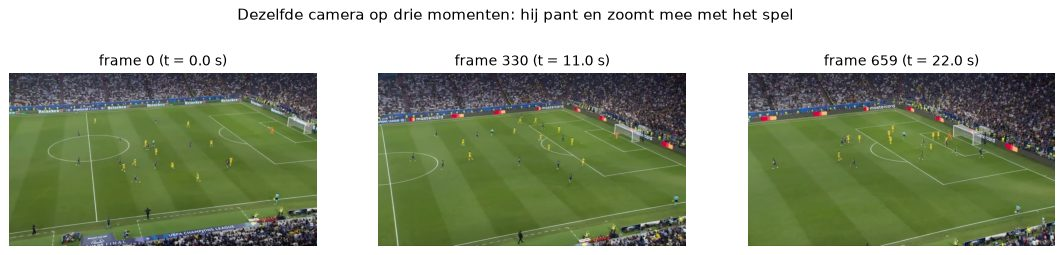

In [2]:
show = [0, 330, 659]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, i in zip(axes, show):
    ax.imshow(rgb(read_frame(VIDEO, i)))
    ax.set_title(f"frame {i} (t = {i / info['fps']:.1f} s)")
    ax.axis("off")
fig.suptitle("Dezelfde camera op drie momenten: hij pant en zoomt mee met het spel", y=1.02)
show_photo(fig, "01_camera_beweegt.png")

**Wat zien we:** in frame 0 staat de middencirkel links in beeld, in frame 330 nog maar een stuk ervan aan de linkerrand, en in frame
659 is de camera ingezoomd op het rechterstrafschopgebied. Elke frame heeft dus zijn eigen omrekening nodig.

**Het veldmodel** (`core/pitch.py`) beschrijft het veld in meters volgens de FIFA-maten (105 x 68 m, strafschopgebied
16,5 x 40,32 m, doelgebied 5,5 x 18,32 m, stip op 11 m, cirkel met straal 9,15 m). Het assenstelsel volgt de
oriëntatie van het tv-beeld:

- **oorsprong (0, 0)** = de hoek van de verre zijlijn (boven in beeld) en de linkerdoellijn;
- **x** loopt langs de zijlijn van 0 (linkerdoel) tot 105 m (rechterdoel);
- **y** loopt over de breedte van 0 (verre zijlijn, boven in beeld) tot 68 m (dichtbije zijlijn, onder in beeld, waar de camera staat).

Zo staat de minimap "rechtop" zoals het tv-beeld: wat in het beeld rechts staat, staat ook op de minimap rechts.
Het model kent 31 benoemde punten (hoeken, snijpunten van lijnen, de stippen, de snijpunten van de cirkelbogen met de
lijnen). Die punten zijn wat we in het beeld kunnen aanklikken.

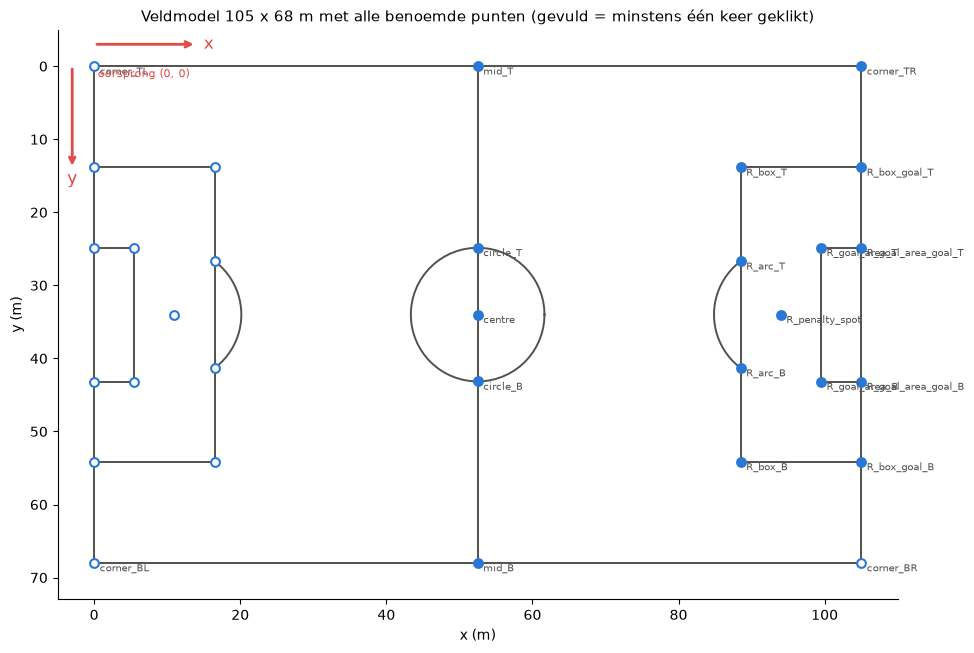

punt,corner_TL,corner_TR,corner_BL,corner_BR,mid_T,mid_B,centre,circle_T,circle_B,R_box_goal_T,R_box_goal_B,R_box_T,R_box_B,R_goal_area_goal_T,R_goal_area_goal_B,R_goal_area_T,R_goal_area_B,R_penalty_spot,R_arc_T,R_arc_B
x (m),0.0,105.0,0.0,105.0,52.5,52.5,52.5,52.50,52.50,105.00,105.00,88.50,88.50,105.00,105.00,99.50,99.50,94.0,88.50,88.50
y (m),0.0,0.0,68.0,68.0,0.0,68.0,34.0,24.85,43.15,13.84,54.16,13.84,54.16,24.84,43.16,24.84,43.16,34.0,26.69,41.31


In [3]:
fig, ax = plt.subplots(figsize=(11, 7.4))
draw_pitch(ax, lw=1.4)
used = {n for pts in keypoints.values() for n in pts}
for name, (x, y) in KEYPOINTS.items():
    ax.scatter(x, y, s=40, zorder=3, color=C["main"] if name in used else "white",
               edgecolor=C["main"], linewidth=1.5)
    if name.startswith("R_") or not name.startswith("L_"):
        ax.annotate(name, (x, y), xytext=(4, -6), textcoords="offset points", fontsize=7, color=C["ink"])
ax.annotate("", xy=(14, -3), xytext=(0, -3), arrowprops=dict(arrowstyle="->", color=C["warn"], lw=2))
ax.annotate("", xy=(-3, 14), xytext=(-3, 0), arrowprops=dict(arrowstyle="->", color=C["warn"], lw=2))
ax.text(15, -3, "x", color=C["warn"], va="center", fontsize=12)
ax.text(-3, 16, "y", color=C["warn"], ha="center", fontsize=12)
ax.text(0.5, 1.5, "oorsprong (0, 0)", color=C["warn"], fontsize=8)
ax.set_title("Veldmodel 105 x 68 m met alle benoemde punten (gevuld = minstens één keer geklikt)")
save(fig, "02_veldmodel.png")
plt.show()

pd.DataFrame([(n, x, y) for n, (x, y) in KEYPOINTS.items() if not n.startswith("L_")],
             columns=["punt", "x (m)", "y (m)"]).round(2).set_index("punt").T

De tabel toont de coördinaten van de rechterhelft en de middellijn; de linkerhelft is het spiegelbeeld (x -> 105 - x).
Alleen gevulde punten zijn ooit geklikt: de camera ziet in deze clip nooit de linkerhelft (zie sectie 4).

## 2. De theorie: wat is een homografie?

**Homogene coördinaten.** Een beeldpunt $(u, v)$ schrijven we als $(u, v, 1)$. Een homografie is een 3x3-matrix $H$
met

$$\begin{pmatrix} x' \\ y' \\ w \end{pmatrix} = H \begin{pmatrix} u \\ v \\ 1 \end{pmatrix}, \qquad
(X, Y) = \left(\frac{x'}{w}, \frac{y'}{w}\right)$$

waarbij $(X, Y)$ de positie op het veld in meters is. De deling door $w$ maakt de afbeelding niet-lineair: zo kan ze
perspectief beschrijven (evenwijdige lijnen op het veld lopen in het beeld naar een verdwijnpunt).

**8 vrijheidsgraden.** $H$ heeft 9 getallen, maar $H$ en $2H$ geven hetzelfde resultaat (de schaal valt weg bij de deling).
Er blijven dus 8 onbekenden over. Elk puntpaar (beeldpunt <-> veldpunt) levert 2 vergelijkingen (één voor $X$, één voor
$Y$), dus **minstens 4 puntparen** zijn nodig, waarvan geen 3 op één lijn. Met precies 4 punten is de oplossing exact
en is er geen controle mogelijk; met meer punten zoeken we de beste benadering en vertelt de restfout hoe goed de klikken zijn.

**Alleen in het veldvlak.** Een homografie beeldt één vlak af op één ander vlak. Het geldt voor alles wat **op het gras
ligt**: lijnen, voeten, een rollende bal. Een punt boven het gras (een hoofd, een bal in de lucht) ligt niet in dat
vlak; de matrix behandelt het alsof het op het gras ligt, op de plek waar de kijklijn van de camera het gras raakt. Dat
is altijd verder van de camera dan de echte voetpositie (zie 7.2).

**Hoe vind je H?** De standaardmethode is de *Direct Linear Transform* (DLT): schrijf elke vergelijking
$X \cdot (h_{31}u + h_{32}v + h_{33}) = h_{11}u + h_{12}v + h_{13}$ (en idem voor $Y$) als een lineaire rij in de 9
onbekenden, stapel alle rijen in een matrix $A$ en zoek de vector $h$ met $\|h\| = 1$ die $\|Ah\|$ minimaliseert: de
laatste rechtssinguliere vector uit de SVD van $A$. Vooraf normaliseren we beide puntenwolken (verschuiven naar het
zwaartepunt, schalen naar gemiddelde afstand $\sqrt{2}$), anders is het stelsel numeriek slecht geconditioneerd.
`cv2.findHomography` doet in essentie hetzelfde en verfijnt daarna nog met een niet-lineaire optimalisatie van de
terugprojectiefout.

**RANSAC** (*random sample consensus*) helpt als er foute puntparen tussen zitten: het fit herhaaldelijk een $H$ op 4
willekeurige paren, telt hoeveel andere paren daar binnen een drempel bij passen (*inliers*), houdt de beste en fit
opnieuw op alle inliers. Eén misklik of een verkeerd benoemd punt trekt de oplossing dan niet scheef. Bij precies 4 punten
heeft RANSAC geen zin (er is niets om tegen te controleren). De app (`core/homography.py`, functie `fit`) gebruikt
daarom: 4 punten -> exacte oplossing; 5 of meer -> RANSAC met een drempel van **1,0 m op het veld**.

Hieronder rekenen we $H$ voor keyframe 0 (10 geklikte punten) op drie manieren uit.

In [4]:
def dlt(img_pts, pitch_pts):
    # Normalised Direct Linear Transform: H with pitch ~ H @ image (homogeneous), H[2, 2] = 1
    def normalise(p):
        c = p.mean(axis=0)
        s = np.sqrt(2) / np.mean(np.linalg.norm(p - c, axis=1))
        T = np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1]])
        return (np.c_[p, np.ones(len(p))] @ T.T)[:, :2], T

    a, Ta = normalise(np.asarray(img_pts, float))
    b, Tb = normalise(np.asarray(pitch_pts, float))
    rows = []
    for (x, y), (u, v) in zip(a, b):
        rows.append([-x, -y, -1, 0, 0, 0, u * x, u * y, u])
        rows.append([0, 0, 0, -x, -y, -1, v * x, v * y, v])
    _, _, Vt = np.linalg.svd(np.array(rows))      # h = right singular vector of the smallest singular value
    H = np.linalg.inv(Tb) @ Vt[-1].reshape(3, 3) @ Ta
    return H / H[2, 2]


k = 0
pts = keypoints[k]
names = list(pts)
img_pts = np.array([pts[n] for n in names], float)
pitch_pts = np.array([KEYPOINTS[n] for n in names], float)

H_dlt = dlt(img_pts, pitch_pts)
H_ls, _ = cv2.findHomography(img_pts, pitch_pts, 0)
H_app, _ = fit(pts)                                # what the app uses (RANSAC from 5 points)

np.set_printoptions(precision=5, suppress=True)
print(f"keyframe {k}: {len(names)} clicked points -> {2 * len(names)} equations for 8 unknowns")
print("H (own DLT, scaled so that H[2,2] = 1):\n", H_dlt)
print("H (core.homography.fit, RANSAC):\n", H_app / H_app[2, 2])

centre = [[W_IMG / 2, H_IMG / 2]]
rows = []
for label, H in [("eigen DLT (numpy SVD)", H_dlt), ("cv2.findHomography, methode 0", H_ls),
                 ("cv2.findHomography, RANSAC (app)", H_app)]:
    err = np.linalg.norm(project(img_pts, H) - pitch_pts, axis=1)
    rows.append({"methode": label, "RMSE geklikte punten (m)": np.sqrt(np.mean(err ** 2)),
                 "beeldmidden -> veld (x, y) in m": tuple(np.round(project(centre, H)[0], 2))})
pd.DataFrame(rows).set_index("methode").round(3)

keyframe 0: 10 clicked points -> 20 equations for 8 unknowns
H (own DLT, scaled so that H[2,2] = 1):
 [[   0.09283    0.1657    10.44169]
 [   0.02573    0.40813 -114.55251]
 [   0.00003    0.00331    1.     ]]
H (core.homography.fit, RANSAC):
 [[   0.09307    0.16642   10.49334]
 [   0.02592    0.40996 -115.24499]
 [   0.00003    0.00332    1.     ]]


,RMSE geklikte punten (m),"beeldmidden -> veld (x, y) in m"
methode,,
eigen DLT (numpy SVD),0.223,"(67.04, 46.29)"
"cv2.findHomography, methode 0",0.215,"(67.07, 46.32)"
"cv2.findHomography, RANSAC (app)",0.215,"(67.07, 46.32)"


**Wat zien we:** onze eigen DLT van een tiental regels numpy geeft bijna dezelfde matrix als OpenCV. Het beeldmidden komt
met beide op ongeveer (67,1 m; 46,3 m) terecht, en de geklikte punten liggen gemiddeld 0,22 m van hun echte positie.
OpenCV is iets beter (0,215 m) omdat het na de DLT nog de echte afstandsfout minimaliseert in plaats van de algebraïsche
fout. RANSAC verandert hier niets: alle 10 klikken zijn inliers. Ook in de rest van de data markeert RANSAC geen enkele klik als
uitschieter (0 van de 269 klikken op keyframes met minstens 5 punten, zie de volgende cel). De demonstratie hieronder
laat zien wat er gebeurt als er wel een misklik tussen zit.

De derde rij van $H$ is niet $(0, 0, 1)$: dat is het perspectieve deel. Een *affiene* transformatie (6 vrijheidsgraden,
derde rij vast) kan het perspectief van een schuin camerabeeld niet beschrijven.

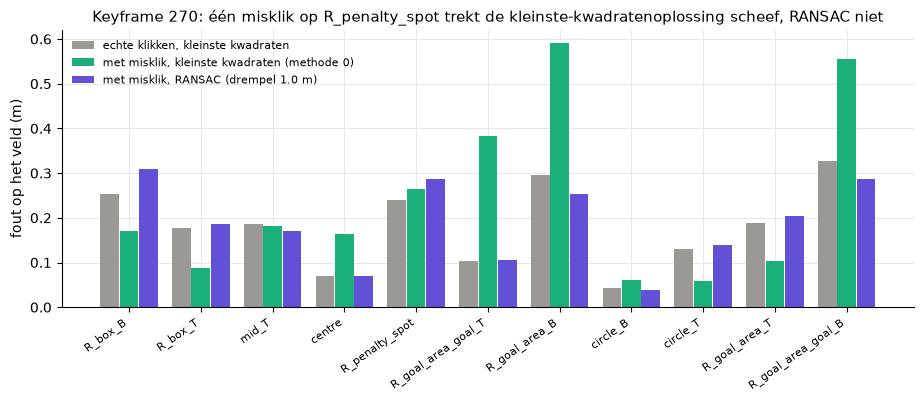

RANSAC marks as outlier: ['R_penalty_spot']
real data: 0 RANSAC outliers over 269 clicks
RMSE (m) - reference 0.203 | least squares 0.300 | RANSAC 0.206


In [5]:
# RANSAC versus plain least squares: one deliberate misclick on keyframe 270 (11 points)
k = 270
pts = {n: list(v) for n, v in keypoints[k].items()}
names = list(pts)
bad = "R_penalty_spot" if "R_penalty_spot" in pts else names[0]
wrong = dict(pts)
wrong[bad] = [pts[bad][0] + 25, pts[bad][1] + 15]           # 29 px off: a realistic misclick
img_w = np.array([wrong[n] for n in names], float)
pit = np.array([KEYPOINTS[n] for n in names], float)
img_ok = np.array([pts[n] for n in names], float)

H_ls, _ = cv2.findHomography(img_w, pit, 0)
H_rs, inl = cv2.findHomography(img_w, pit, cv2.RANSAC, RANSAC_M)
H_ref, _ = cv2.findHomography(img_ok, pit, 0)                # reference: the real clicks

# Error of every CORRECT click position when mapped with each H (metres on the pitch)
err_ls = np.linalg.norm(project(img_ok, H_ls) - pit, axis=1)
err_rs = np.linalg.norm(project(img_ok, H_rs) - pit, axis=1)
err_ref = np.linalg.norm(project(img_ok, H_ref) - pit, axis=1)

fig, ax = plt.subplots(figsize=(11, 3.6))
xx = np.arange(len(names))
ax.bar(xx - 0.27, err_ref, 0.26, color=C["grey"], label="echte klikken, kleinste kwadraten")
ax.bar(xx, err_ls, 0.26, color=C["second"], label="met misklik, kleinste kwadraten (methode 0)")
ax.bar(xx + 0.27, err_rs, 0.26, color=C["third"], label=f"met misklik, RANSAC (drempel {RANSAC_M} m)")
ax.set_xticks(xx, names, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("fout op het veld (m)")
ax.set_title(f"Keyframe {k}: één misklik op {bad} trekt de kleinste-kwadratenoplossing scheef, RANSAC niet")
ax.legend(fontsize=8)
plt.show()
print("RANSAC marks as outlier:", [n for n, m in zip(names, inl.ravel()) if not m])
# And on the real clicks? Count RANSAC outliers over all keyframes with >= 5 points
n_out = 0
for f, p in keypoints.items():
    if len(p) >= 5:
        _, m = cv2.findHomography(np.array(list(p.values()), float), np.array([KEYPOINTS[n] for n in p], float),
                                  cv2.RANSAC, RANSAC_M)
        n_out += int((m.ravel() == 0).sum())
print(f"real data: {n_out} RANSAC outliers over {sum(len(p) for p in keypoints.values() if len(p) >= 5)} clicks")
print(f"RMSE (m) - reference {np.sqrt(np.mean(err_ref**2)):.3f} | least squares {np.sqrt(np.mean(err_ls**2)):.3f}"
      f" | RANSAC {np.sqrt(np.mean(err_rs**2)):.3f}")

**Wat zien we:** we verschuiven op keyframe 270 één klik (de strafschopstip) 29 pixels, een realistische misklik. Met
gewone kleinste kwadraten verschuift de hele oplossing: de RMSE van de **juiste** posities stijgt van 0,20 naar 0,30 m,
en ook punten ver van de misklik worden slechter. RANSAC herkent de stip als uitschieter, fit zonder hem en blijft op
0,21 m. Daarom gebruikt de app RANSAC vanaf 5 punten.

## 3. De geklikte keypoints

De veldpunten zijn met de hand aangeklikt met `click_keypoints.py` (in `../streamlit/`). Dat programma toont een
keyframe, je kiest een punt op een kleine minimap en klikt het in het beeld; een vergrootglas helpt om precies te klikken.
Vanaf 4 punten tekent het de teruggeprojecteerde veldlijnen over het beeld, vanaf 5 punten toont het per punt de fout in
pixels. De klikken staan in `../data/keypoints.json` als `{frame: {puntnaam: [x_px, y_px]}}`.

Eerst is elke 30e frame geklikt (0, 30, ..., 630, en de laatste frame 659; de standaardinstelling van de kliktool), daarna nog 13 extra keyframes daartussen (43, 226, 314, 322, ...).

39 keyframes, 305 klikken in totaal; punten per keyframe: min 4, mediaan 9, max 12
afstand tussen keyframes: mediaan 14 frames, max 30 frames (1.0 s)
keyframes met precies 4 punten (niet controleerbaar): [30, 90, 120, 150, 180, 240, 433, 497, 570]
17 van de 31 veldpunten zijn ooit geklikt; nooit: ['corner_BL', 'corner_BR', 'corner_TL'] + alle 11 punten van de linkerhelft


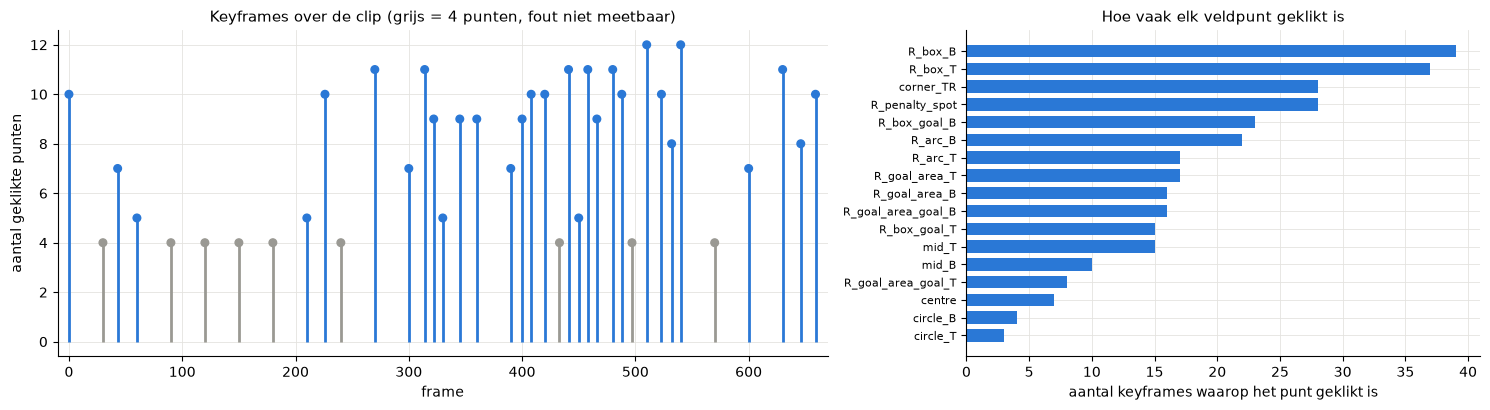

In [6]:
kf = pd.DataFrame([{"frame": f, "n_punten": len(p), "punten": ", ".join(sorted(p))} for f, p in sorted(keypoints.items())])
kf["gat_tot_volgende"] = kf["frame"].shift(-1) - kf["frame"]
print(f"{len(kf)} keyframes, {kf.n_punten.sum()} klikken in totaal; "
      f"punten per keyframe: min {kf.n_punten.min()}, mediaan {kf.n_punten.median():.0f}, max {kf.n_punten.max()}")
print(f"afstand tussen keyframes: mediaan {kf.gat_tot_volgende.median():.0f} frames, "
      f"max {kf.gat_tot_volgende.max():.0f} frames ({kf.gat_tot_volgende.max() / info['fps']:.1f} s)")
print(f"keyframes met precies 4 punten (niet controleerbaar): {kf.frame[kf.n_punten == 4].tolist()}")
usage = pd.Series([n for p in keypoints.values() for n in p]).value_counts()
print(f"{len(usage)} van de {len(KEYPOINTS)} veldpunten zijn ooit geklikt; nooit: "
      f"{sorted(set(KEYPOINTS) - set(usage.index) - {n for n in KEYPOINTS if n.startswith('L_')})} "
      f"+ alle {sum(n.startswith('L_') for n in KEYPOINTS)} punten van de linkerhelft")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
colours = [C["grey"] if n == 4 else C["main"] for n in kf.n_punten]
ax.vlines(kf.frame, 0, kf.n_punten, color=colours, lw=2)
ax.scatter(kf.frame, kf.n_punten, color=colours, s=30, zorder=3)
ax.set_xlim(-10, N + 10)
ax.set_xlabel("frame")
ax.set_ylabel("aantal geklikte punten")
ax.set_title("Keyframes over de clip (grijs = 4 punten, fout niet meetbaar)")
ax = axes[1]
ax.barh(usage.index[::-1], usage.values[::-1], color=C["main"], height=0.7)
ax.set_xlabel("aantal keyframes waarop het punt geklikt is")
ax.set_title("Hoe vaak elk veldpunt geklikt is")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
save(fig, "03_keyframes_en_punten.png")
plt.show()

**Wat zien we:**
- 39 keyframes met samen 305 klikken, 4 tot 12 per frame (mediaan 9). Tussen twee keyframes zitten hooguit 30 frames
  (1 s), meestal 14.
- 9 keyframes hebben precies 4 punten (grijs). Daar is $H$ exact bepaald en is de fout dus per definitie 0: die frames
  kunnen we niet controleren. Ze liggen vooral in het begin (30-240) en verder op 433, 497 en 570.
- Slechts 17 van de 31 modelpunten zijn ooit gebruikt, bijna allemaal rond het **rechterstrafschopgebied**
  (`R_box_B`, `R_box_T`, `corner_TR`, de stip). De linkerhelft is nooit in beeld.

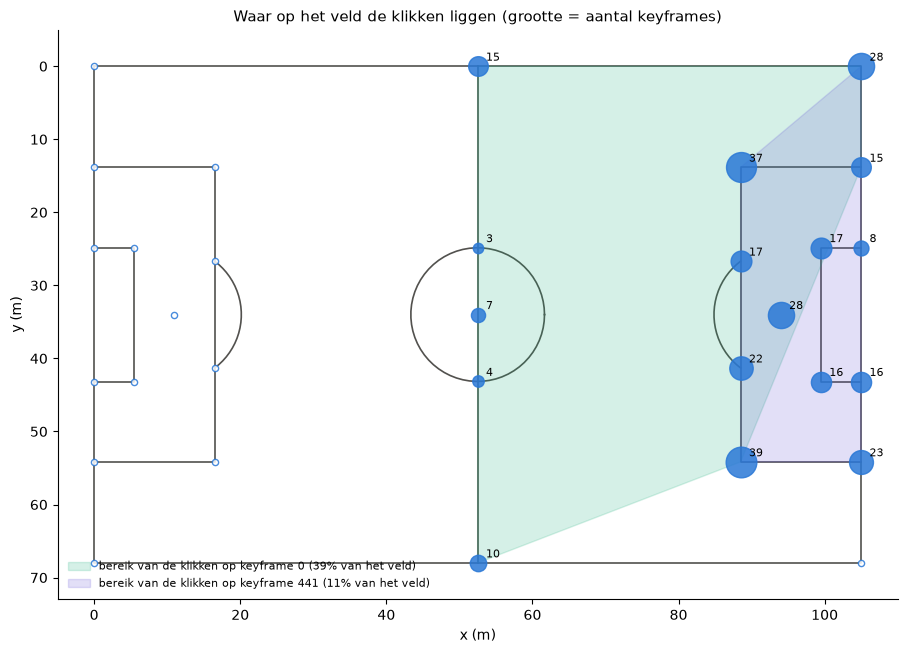

In [7]:
fig, ax = plt.subplots(figsize=(11, 7.4))
draw_pitch(ax, lw=1.2)
for name, (x, y) in KEYPOINTS.items():
    n = usage.get(name, 0)
    ax.scatter(x, y, s=20 + 12 * n, color=C["main"] if n else "white", edgecolor=C["main"], alpha=0.85, zorder=3)
    if n:
        ax.annotate(str(n), (x, y), xytext=(6, 4), textcoords="offset points", fontsize=8)
for f, colour in ((0, C["second"]), (441, C["third"])):
    hull = cv2.convexHull(np.array([KEYPOINTS[n] for n in keypoints[f]], np.float32)).reshape(-1, 2)
    ax.fill(hull[:, 0], hull[:, 1], color=colour, alpha=0.18, zorder=2,
            label=f"bereik van de klikken op keyframe {f} ({100 * spread_check(keypoints[f])['hull_frac']:.0f}% van het veld)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Waar op het veld de klikken liggen (grootte = aantal keyframes)")
save(fig, "04_spreiding_klikken.png")
plt.show()

**Wat zien we:** op keyframe 0 omspannen de klikken een groot deel van het veld (van de middenlijn tot het
rechterdoel). Vanaf frame ±390 is de camera ingezoomd en liggen alle klikken in en rond het strafschopgebied: ze omspannen
dan maar ongeveer een tiende van het veld. Voor spelers buiten dat gebied moet $H$ **extrapoleren**, wat minder
nauwkeurig is (sectie 5.3 meet hoeveel).

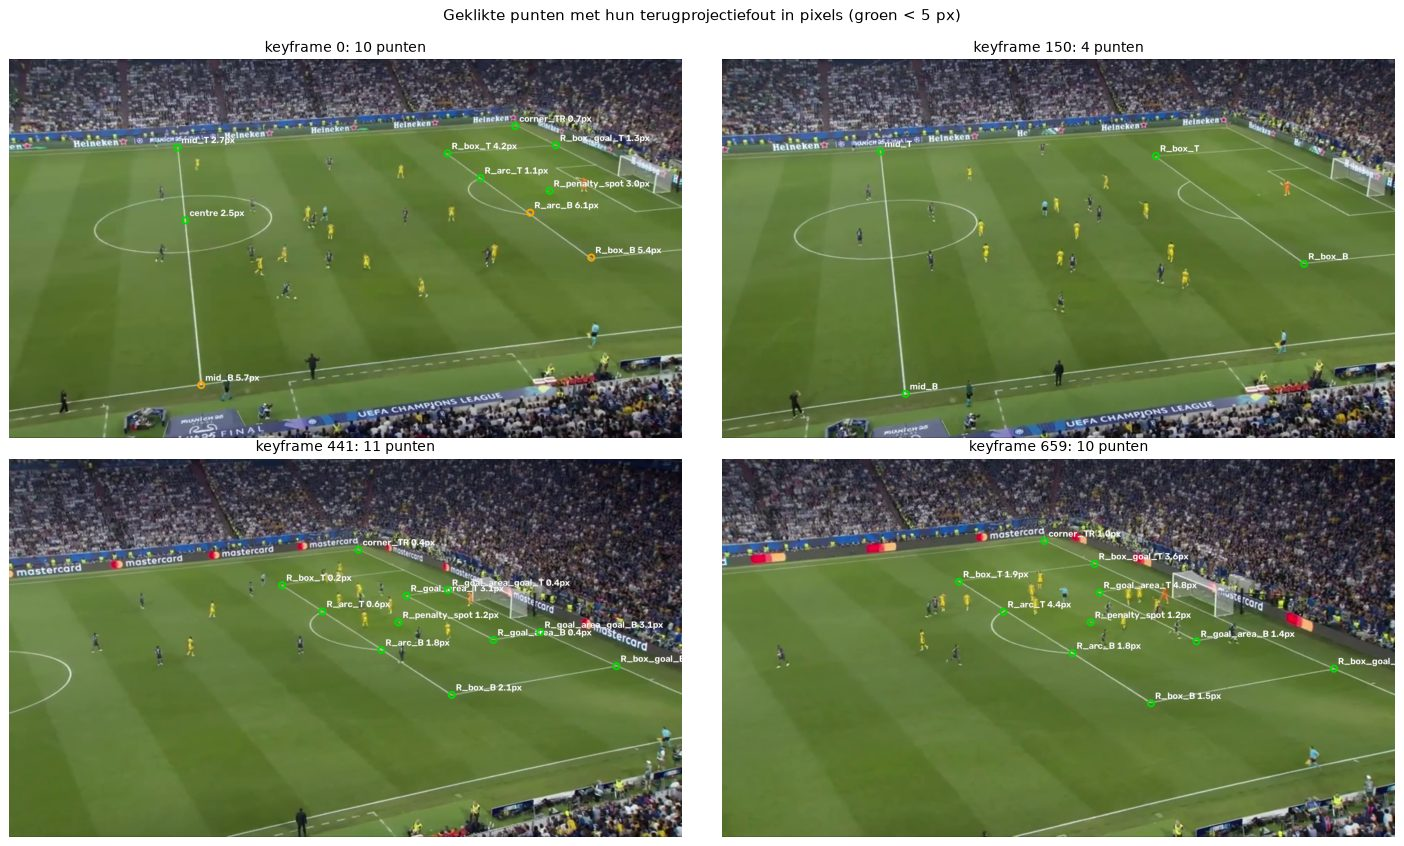

In [8]:
def draw_clicks(frame, pts, errors):
    out = frame.copy()
    for name, (x, y) in pts.items():
        e = errors.get(name, 0.0) if len(pts) >= 5 else 0.0
        col = (0, 220, 0) if e < 5 else (0, 165, 255) if e < 10 else (0, 0, 255)
        cv2.circle(out, (int(x), int(y)), 9, col, 3, cv2.LINE_AA)
        txt = f"{name} {e:.1f}px" if len(pts) >= 5 else name
        cv2.putText(out, txt, (int(x) + 12, int(y) - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 0), 6, cv2.LINE_AA)
        cv2.putText(out, txt, (int(x) + 12, int(y) - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
    return out


fig, axes = plt.subplots(2, 2, figsize=(16, 9.4))
for ax, f in zip(axes.ravel(), [0, 150, 441, 659]):
    H, errors = fit(keypoints[f])
    ax.imshow(rgb(draw_clicks(read_frame(VIDEO, f), keypoints[f], errors)))
    ax.set_title(f"keyframe {f}: {len(keypoints[f])} punten")
    ax.axis("off")
fig.suptitle("Geklikte punten met hun terugprojectiefout in pixels (groen < 5 px)", y=0.995)
fig.tight_layout()
show_photo(fig, "05_keyframes_met_klikken.png")

**Wat zien we:** de klikken liggen op duidelijke snijpunten van witte lijnen. Het getal achter elke naam is de afstand
in pixels tussen de klik en waar de gefitte $H$ het punt terugzet. Op de getoonde frames is de grootste afwijking 6,1 px; op
keyframe 150 (4 punten) staat geen getal omdat de fout daar altijd 0 is. Merk op hoe keyframe 150 enkel de middenlijn en
de twee hoeken van het strafschopgebied gebruikt: dat is genoeg voor een exacte $H$, maar een misklik zou onopgemerkt blijven.

## 4. Van 39 keyframes naar 660 frames

De app heeft voor elk van de 660 frames een $H$ nodig, maar er zijn er maar 39 geklikt. Wat `Homographies._for_frame`
in `core/homography.py` precies doet:

1. **Op een keyframe** gebruikt het de $H$ die op de klikken van dat frame gefit is (exact bij 4 punten, RANSAC vanaf 5).
2. **Tussen twee keyframes** $a < t < b$ berekent het $\tau = (t - a) / (b - a)$. Een vast rooster van 30 veldpunten
   (`GRID`: 6 x 5 punten, x = 0, 21, ..., 105 m en y = 0, 17, ..., 68 m) wordt met $H_a^{-1}$ en $H_b^{-1}$ in beide
   keyframes geprojecteerd. De **pixelposities** van die 30 punten worden lineair geïnterpoleerd,
   $p(t) = (1 - \tau)\,p_a + \tau\,p_b$, en op die 30 geïnterpoleerde puntparen wordt opnieuw een $H$ gefit
   (`cv2.findHomography`, kleinste kwadraten zonder RANSAC).
3. **Voor de eerste of na de laatste keyframe** neemt het de dichtstbijzijnde keyframe. In onze data zijn frame 0 en
   frame 659 zelf keyframes, dus dat geval komt niet voor.
4. Het resultaat wordt per frame bewaard (`lru_cache`), zodat elke frame maar één keer berekend wordt.

Het alternatief, de 9 getallen van $H_a$ en $H_b$ rechtstreeks middelen, hangt af van hoe elke matrix geschaald is
($H$ en $2H$ zijn dezelfde homografie, maar geven een ander gemiddelde). Punten interpoleren en opnieuw fitten heeft dat
probleem niet en werkt in de grootheid die we zien: posities in het beeld. Het blijft wel een benadering: een echte pan of zoom verschuift pixels niet
lineair in de tijd, en het rooster bevat ook punten die buiten beeld liggen (de linkerhelft), die toch even zwaar
meetellen in de fit. Omdat de keyframes hoogstens 1 s uit elkaar liggen, is dat effect klein; sectie 5.4 meet het.

Hieronder volgen we met de geïnterpoleerde matrices waar het beeldmidden op het veld terechtkomt en hoeveel veld er per
frame in beeld is (aantal punten van een rooster van 0,5 m dat binnen het beeld valt).

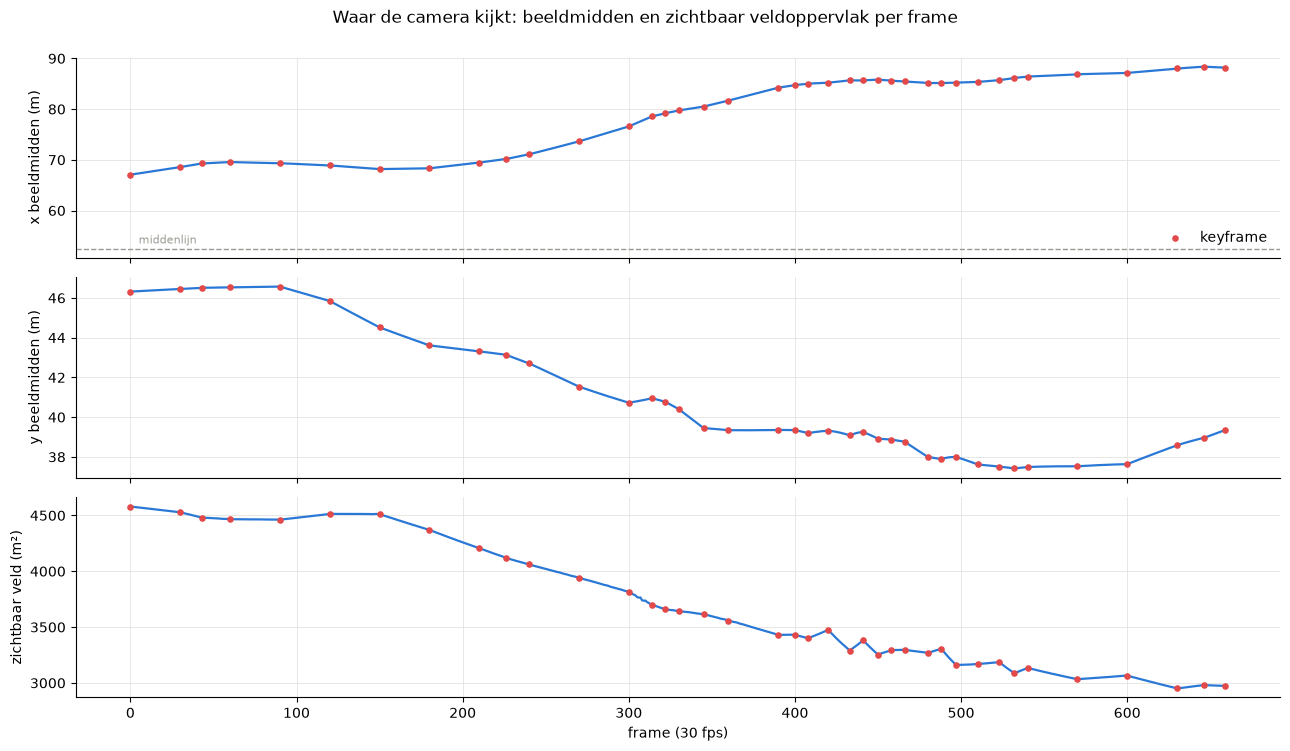

     centre_x  centre_y  visible_m2
min      67.1      37.4      2950.8
50%      79.7      40.4      3644.0
max      88.4      46.6      4579.8
fastest pan of the image centre: 4.2 m/s around frame 305; 
leftmost visible pitch point over all frames: x = 30.0 m (frame 0)


In [9]:
# Where does the image centre land on the pitch, and how much of the pitch is in view? (all 660 frames)
gx, gy = np.meshgrid(np.arange(0, LENGTH + 0.01, 0.5), np.arange(0, WIDTH + 0.01, 0.5))
pitch_grid = np.c_[gx.ravel(), gy.ravel()]
rows = []
for f in range(N):
    cx, cy = hs.image_to_pitch([[W_IMG / 2, H_IMG / 2]], f)[0]
    img = hs.pitch_to_image(pitch_grid, f)
    inside = (img[:, 0] >= 0) & (img[:, 0] < W_IMG) & (img[:, 1] >= 0) & (img[:, 1] < H_IMG)
    rows.append({"frame": f, "centre_x": cx, "centre_y": cy, "visible_m2": inside.sum() * 0.25,
                 "min_visible_x": pitch_grid[inside, 0].min(),
                 "keyframe": f in hs.keyframes})
view = pd.DataFrame(rows)

fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
for ax, col, lab in zip(axes, ["centre_x", "centre_y", "visible_m2"],
                        ["x beeldmidden (m)", "y beeldmidden (m)", "zichtbaar veld (m²)"]):
    ax.plot(view.frame, view[col], color=C["main"], lw=1.6)
    k = view[view.keyframe]
    ax.scatter(k.frame, k[col], color=C["warn"], s=14, zorder=3, label="keyframe")
    ax.set_ylabel(lab)
axes[0].axhline(LENGTH / 2, color=C["grey"], lw=1, ls="--")
axes[0].text(5, LENGTH / 2 + 1, "middenlijn", color=C["grey"], fontsize=8)
axes[0].legend(loc="lower right")
axes[-1].set_xlabel("frame (30 fps)")
fig.suptitle("Waar de camera kijkt: beeldmidden en zichtbaar veldoppervlak per frame", y=0.995)
fig.tight_layout()
save(fig, "06_camerabeweging.png")
plt.show()
print(view[["centre_x", "centre_y", "visible_m2"]].describe().loc[["min", "50%", "max"]].round(1))
speed = view.centre_x.diff(10).abs() / 10 * info["fps"]          # m/s of the image centre over 10 frames
print(f"fastest pan of the image centre: {speed.max():.1f} m/s around frame {int(view.frame[speed.idxmax()]) - 5}; "
      )
print(f"leftmost visible pitch point over all frames: x = {view.min_visible_x.min():.1f} m "
      f"(frame {int(view.frame[view.min_visible_x.idxmin()])})")

**Wat zien we:** het beeldmidden schuift in de clip van x ≈ 67 m (15 m rechts van de middenlijn) naar x ≈ 88 m (de rand
van het rechterstrafschopgebied); het zichtbare veld krimpt van ±4580 m² naar ±2950 m² (van 64 % naar 41 % van de
7140 m² van het veld) doordat de camera inzoomt. Het beeldmidden beweegt het snelst rond frame 305 (4,2 m/s over het
veld); daar zijn ook extra keyframes geklikt (300, 314, 322, 330, 345).

Let op hoe je deze figuur leest: tussen twee keyframes (rode punten) zijn de curven bijna rechte stukken. Dat is de
lineaire interpolatie zelf, niet noodzakelijk de echte camerabeweging. De figuur toont dus waar de camera kijkt
volgens de keyframes; of de interpolatie daartussen klopt, meten we in sectie 5.4 en 5.5.

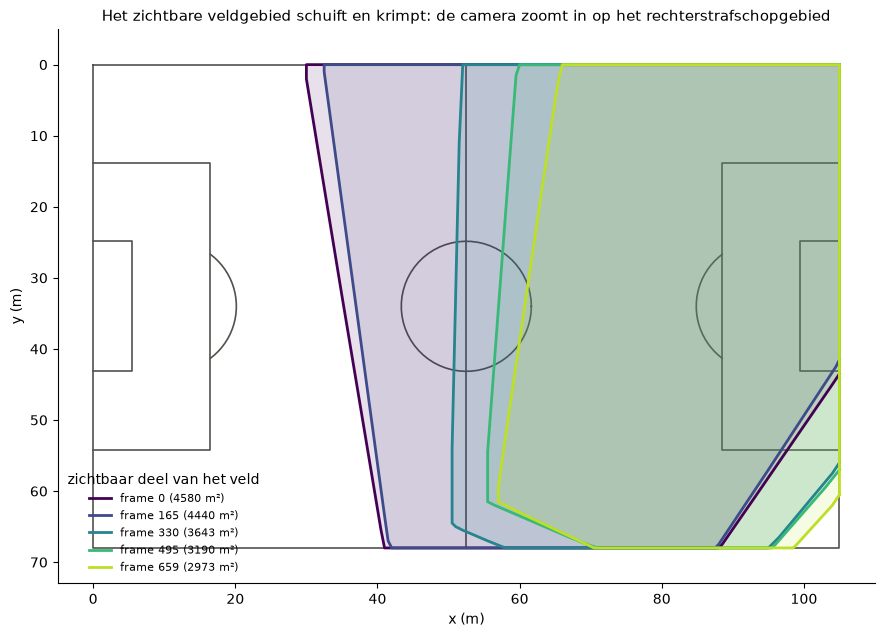

In [10]:
fig, ax = plt.subplots(figsize=(11, 7.2))
draw_pitch(ax, lw=1.2)
frames_show = [0, 165, 330, 495, 659]
cmap = plt.get_cmap("viridis")
for j, f in enumerate(frames_show):
    img = hs.pitch_to_image(pitch_grid, f)
    inside = (img[:, 0] >= 0) & (img[:, 0] < W_IMG) & (img[:, 1] >= 0) & (img[:, 1] < H_IMG)
    hull = cv2.convexHull(pitch_grid[inside].astype(np.float32)).reshape(-1, 2)
    col = cmap(j / (len(frames_show) - 1) * 0.9)
    ax.fill(hull[:, 0], hull[:, 1], color=col, alpha=0.12)
    ax.plot(np.r_[hull[:, 0], hull[0, 0]], np.r_[hull[:, 1], hull[0, 1]], color=col, lw=2,
            label=f"frame {f} ({view.visible_m2[f]:.0f} m²)")
ax.legend(loc="lower left", fontsize=8, title="zichtbaar deel van het veld")
ax.set_title("Het zichtbare veldgebied schuift en krimpt: de camera zoomt in op het rechterstrafschopgebied")
save(fig, "07_zichtbaar_veld.png")
plt.show()

**Wat zien we:** de camera ziet in deze clip nooit verder naar links dan x ≈ 30 m. De linkerhelft en het linkerdoel
komen nooit in beeld; dat verklaart waarom geen enkel `L_`-punt geklikt is. Het zichtbare deel is telkens een trapezium:
de verre zijlijn (boven) beslaat in het beeld veel meer meters dan de dichtbije (onder), het typische perspectief van een
hoog opgestelde camera.

## 5. Kwaliteitscontrole

We controleren de homografie op vier manieren, van "zit de klik goed" tot "klopt de interpolatie":

| Controle | Wat meet ze | Waar |
|---|---|---|
| Reprojectiefout | hoe goed $H$ past op de klikken van zijn eigen keyframe | 5.1 |
| Spreidingscheck | of de klikken genoeg verspreid liggen (niet op één lijn, niet op een kluitje) | 5.2 |
| Eén punt weglaten | hoe goed $H$ een punt voorspelt dat niet in de fit zat (vooral buiten het klikgebied) | 5.3 |
| Eén keyframe weglaten / witte-lijnscore | hoeveel de geïnterpoleerde $H$ tussen keyframes afwijkt | 5.4, 5.5 |

De eerste en de laatste controle zijn de checks van `check_homography.py`; hun uitkomst staat in
`../data/results/homografie/homography_reprojection.csv` en `homography_check.csv`. We rekenen ze hier opnieuw uit en
vergelijken. De controles 5.3 en 5.4 zijn nieuw in dit notebook.

De **reprojectiefout** van een keyframe: zet elk geklikt pixel met $H$ om naar meters en meet de afstand tot de echte
positie van dat punt in het veldmodel. We rapporteren de RMSE (wortel van het gemiddelde kwadraat) over de punten van het
frame en de grootste afzonderlijke fout. We meten in **meters op het veld**, niet in pixels: een pixel ver weg weegt veel
zwaarder dan een pixel vooraan (zie 7.1), en meters zijn wat de minimap gebruikt.

### 5.1 Reprojectiefout per keyframe

recomputed vs saved csv: 39 keyframes, max |verschil| RMSE 0.0005 m, max |verschil| max-fout 0.0005 m, zelfde slechtste punt: True
controleerbaar (>= 5 punten): 30 van 39; RMSE min 0.065, mediaan 0.164, gemiddeld 0.162, max 0.276 m; grootste fout op één punt 0.664 m (corner_TR op frame 345)


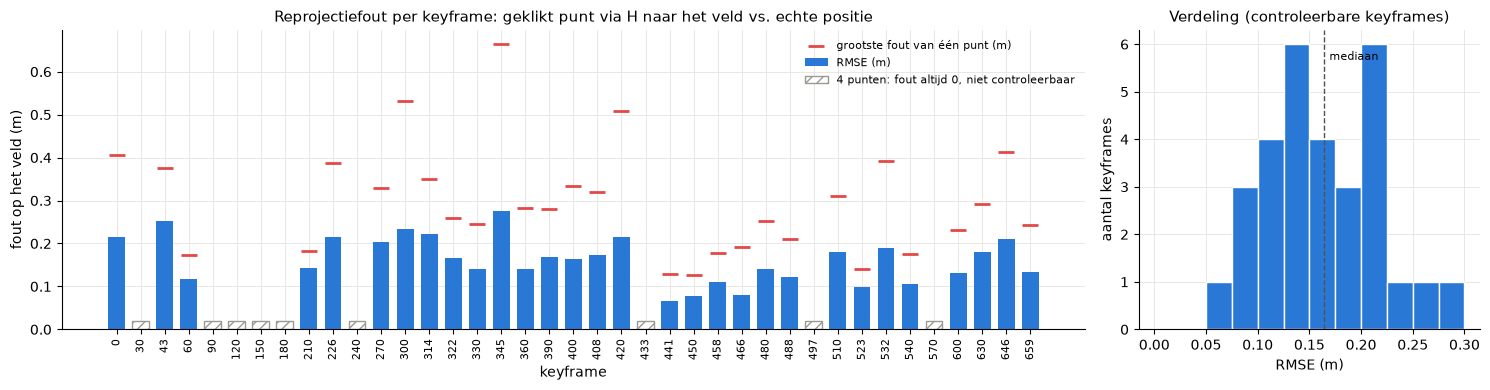

In [11]:
rep = pd.DataFrame(reprojection_report(keypoints))
saved = pd.read_csv(RES / "homography_reprojection.csv")
cmp_ = rep.merge(saved, on="frame", suffixes=("", "_csv"))
print(f"recomputed vs saved csv: {len(cmp_)} keyframes, max |verschil| RMSE "
      f"{(cmp_.rmse_m - cmp_.rmse_m_csv).abs().max():.4f} m, max |verschil| max-fout "
      f"{(cmp_.max_m - cmp_.max_m_csv).abs().max():.4f} m, zelfde slechtste punt: {(cmp_.worst == cmp_.worst_csv).all()}")

chk = rep[rep.checkable]
print(f"controleerbaar (>= 5 punten): {len(chk)} van {len(rep)}; RMSE min {chk.rmse_m.min():.3f}, "
      f"mediaan {chk.rmse_m.median():.3f}, gemiddeld {chk.rmse_m.mean():.3f}, max {chk.rmse_m.max():.3f} m; "
      f"grootste fout op één punt {chk.max_m.max():.3f} m ({chk.loc[chk.max_m.idxmax(), 'worst']} op frame "
      f"{chk.loc[chk.max_m.idxmax(), 'frame']})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
ax = axes[0]
xx = np.arange(len(rep))
ax.bar(xx[rep.checkable], rep.rmse_m[rep.checkable], color=C["main"], width=0.7, label="RMSE (m)")
ax.scatter(xx[rep.checkable], rep.max_m[rep.checkable], color=C["warn"], marker="_", s=120, lw=2,
           label="grootste fout van één punt (m)", zorder=3)
ax.bar(xx[~rep.checkable], 0.02, color="white", edgecolor=C["grey"], hatch="///", width=0.7,
       label="4 punten: fout altijd 0, niet controleerbaar")
ax.set_xticks(xx, rep.frame, rotation=90, fontsize=8)
ax.set_xlabel("keyframe")
ax.set_ylabel("fout op het veld (m)")
ax.set_title("Reprojectiefout per keyframe: geklikt punt via H naar het veld vs. echte positie")
ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
ax.hist(chk.rmse_m, bins=np.arange(0, 0.32, 0.025), color=C["main"], edgecolor="white")
ax.axvline(chk.rmse_m.median(), color=C["ink"], ls="--", lw=1)
ax.text(chk.rmse_m.median() + 0.005, ax.get_ylim()[1] * 0.9, "mediaan", fontsize=8)
ax.set_xlabel("RMSE (m)")
ax.set_ylabel("aantal keyframes")
ax.set_title("Verdeling (controleerbare keyframes)")
fig.tight_layout()
save(fig, "08_reprojectiefout.png")
plt.show()

**Wat zien we:**
- De herberekening valt samen met de opgeslagen csv (verschil ≤ 0,0005 m, dat is de afronding op 3 decimalen). De
  keypoints zijn dus niet meer veranderd sinds de controle gedraaid is.
- 30 van de 39 keyframes zijn controleerbaar. Hun RMSE ligt tussen **0,07 en 0,28 m**, mediaan **0,16 m**. Geen enkel
  frame komt in de buurt van de waarschuwingsgrens van 1 m uit `core/homography.py`.
- De grootste fout van één punt is 0,66 m (`corner_TR` op frame 345). De hoekvlag ligt helemaal achteraan, waar één
  pixel veel meters is, en de hoek wordt vaak deels verborgen door reclameborden.
- De keyframes vanaf ±440 scoren het best (0,07-0,14 m): de camera is daar ingezoomd en er zijn 9 tot 12 punten op korte
  afstand geklikt.
- Zwakke plekken zijn de **9 keyframes met 4 punten**: hun fout is onbekend, niet nul.

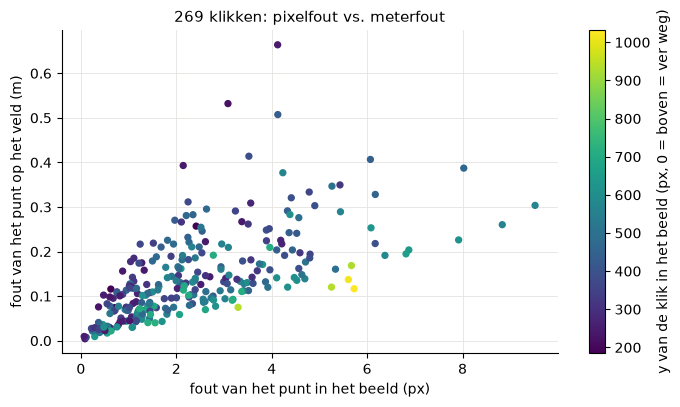

per klik: mediaan 2.1 px = 0.12 m; p95 5.5 px, 0.31 m; 0 klikken > 10 px


In [12]:
# Per-point pixel error vs metre error: the same click error weighs heavier far from the camera
pp = []
for f, pts in keypoints.items():
    if len(pts) < 5:
        continue
    H, err_px = fit(pts)
    err_m = reprojection_errors_m(pts, H)
    for n in pts:
        pp.append({"frame": f, "punt": n, "px": err_px[n], "m": err_m[n], "y_beeld": pts[n][1]})
pp = pd.DataFrame(pp)
fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(pp.px, pp.m, c=pp.y_beeld, cmap="viridis", s=18)
fig.colorbar(sc, ax=ax, label="y van de klik in het beeld (px, 0 = boven = ver weg)")
ax.set_xlabel("fout van het punt in het beeld (px)")
ax.set_ylabel("fout van het punt op het veld (m)")
ax.set_title(f"{len(pp)} klikken: pixelfout vs. meterfout")
plt.show()
print(f"per klik: mediaan {pp.px.median():.1f} px = {pp.m.median():.2f} m; p95 {pp.px.quantile(.95):.1f} px, "
      f"{pp.m.quantile(.95):.2f} m; {int((pp.px > 10).sum())} klikken > 10 px")

**Wat zien we:** de klikken zelf zijn precies: mediaan 2,1 px van waar $H$ ze verwacht, 95 % onder 5,5 px, geen enkele
boven de 10 px (de rode grens in de kliktool). In meters is dat mediaan 0,12 m. Bij dezelfde pixelfout is de meterfout
groter voor klikken hoog in beeld (donkere punten): daar staat de camera ver van het veld.

### 5.2 Spreidingscheck

alle keyframes hebben een goede vierhoek (4 punten zonder 3 bijna op één lijn): True
bereik van de klikken: 4.7% .. 40.5% van het veld; als deel van het zichtbare veld: 10% .. 73%


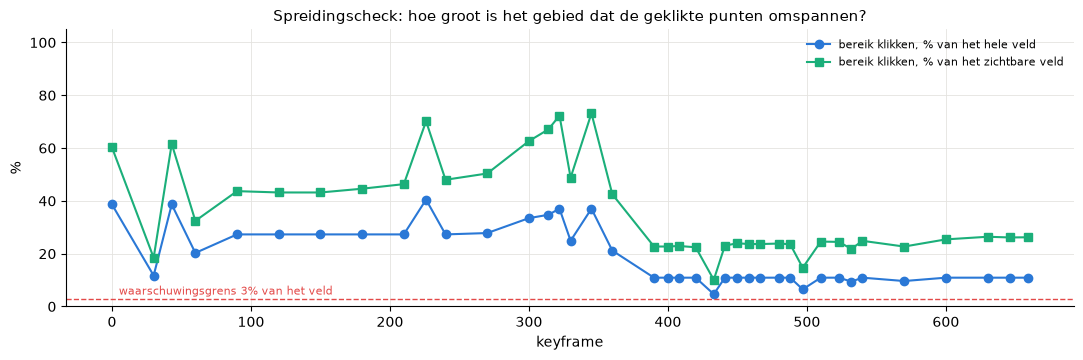

frame,0,30,43,60,90,120,150,180,210,226,...,497,510,523,532,540,570,600,630,646,659
hull_frac,0.386538,0.117176,0.386538,0.202891,0.273076,0.273076,0.273076,0.273076,0.273076,0.404887,...,0.064937,0.109168,0.109168,0.094323,0.109168,0.096458,0.109168,0.109168,0.109168,0.109168
deel_van_zichtbaar,0.602627,0.18477,0.615942,0.324353,0.436945,0.431936,0.431888,0.446169,0.463484,0.70163,...,0.146713,0.245945,0.24469,0.218198,0.248711,0.227053,0.254206,0.264157,0.261542,0.26218
n_collinear,5,0,1,0,0,0,0,0,1,1,...,0,14,14,4,14,0,4,11,2,5
good_quad,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


In [13]:
spread = pd.DataFrame([{"frame": f, **{k: v for k, v in spread_check(p).items() if k != "warnings"}}
                       for f, p in sorted(keypoints.items())])
spread["zichtbaar_m2"] = view.set_index("frame").loc[spread.frame, "visible_m2"].values
spread["hull_m2"] = spread.hull_frac * LENGTH * WIDTH
spread["deel_van_zichtbaar"] = spread.hull_m2 / spread.zichtbaar_m2
print("alle keyframes hebben een goede vierhoek (4 punten zonder 3 bijna op één lijn):", bool(spread.good_quad.all()))
print(f"bereik van de klikken: {spread.hull_frac.min():.1%} .. {spread.hull_frac.max():.1%} van het veld; "
      f"als deel van het zichtbare veld: {spread.deel_van_zichtbaar.min():.0%} .. {spread.deel_van_zichtbaar.max():.0%}")

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(spread.frame, 100 * spread.hull_frac, "o-", color=C["main"], label="bereik klikken, % van het hele veld")
ax.plot(spread.frame, 100 * spread.deel_van_zichtbaar, "s-", color=C["second"], label="bereik klikken, % van het zichtbare veld")
ax.axhline(3, color=C["warn"], ls="--", lw=1)
ax.text(5, 4.5, "waarschuwingsgrens 3% van het veld", color=C["warn"], fontsize=8)
ax.set_xlabel("keyframe")
ax.set_ylabel("%")
ax.set_ylim(0, 105)
ax.set_title("Spreidingscheck: hoe groot is het gebied dat de geklikte punten omspannen?")
ax.legend(fontsize=8, loc="upper right")
save(fig, "09_spreiding.png")
plt.show()
spread[["frame", "hull_frac", "deel_van_zichtbaar", "n_collinear", "good_quad"]].set_index("frame").T.round(2)

**Wat zien we:** alle 39 keyframes hebben minstens vier punten waarvan er geen drie bijna op één lijn liggen
(`good_quad`), dus $H$ is overal goed bepaald. Het waarschuwingsgetal `n_collinear` (aantal drietallen met een
oppervlakte < 5 m²) is hoog op de late frames, maar dat is onschuldig: punten op dezelfde lijn van het strafschopgebied
(bv. `R_box_T`, `R_arc_T`, `R_box_B`) liggen nu eenmaal op één lijn; zolang er daarnaast punten buiten die lijn liggen,
is de fit stabiel.

De echte zwakte zit in het **bereik**: vanaf frame 390 omspannen de klikken maar 9-11 % van het veld en ongeveer een
kwart van wat er in beeld is. Een speler bij de middenlijn ligt dan ver buiten het geklikte gebied.

### 5.3 Kruisvalidatie: één punt weglaten

249 weggelaten punten op 26 keyframes
punt BINNEN het bereik van de andere klikken: n=135, mediaan 0.19 m, p90 0.43 m
punt BUITEN het bereik (extrapolatie):        n=114, mediaan 0.40 m, p90 1.15 m


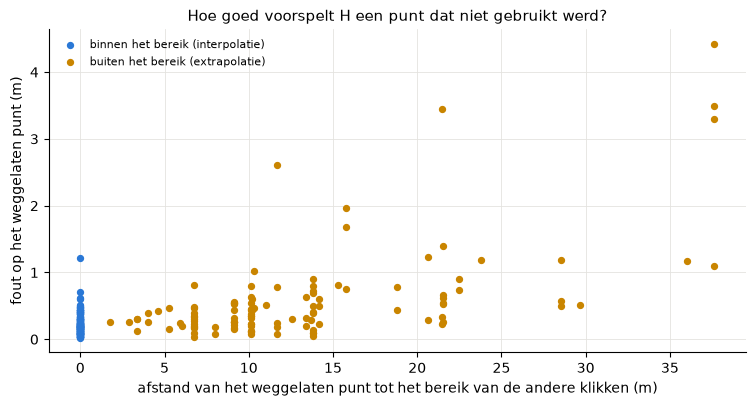

In [14]:
loo = []
for f, pts in sorted(keypoints.items()):
    if len(pts) < 6:                 # need >= 5 points left to fit with RANSAC like the app
        continue
    for n in pts:
        rest = {m: v for m, v in pts.items() if m != n}
        H, _ = fit(rest)
        err = float(np.linalg.norm(project([pts[n]], H)[0] - KEYPOINTS[n]))
        hull = cv2.convexHull(np.array([KEYPOINTS[m] for m in rest], np.float32))
        outside = max(0.0, -cv2.pointPolygonTest(hull, tuple(map(float, KEYPOINTS[n])), True))
        loo.append({"frame": f, "punt": n, "fout_m": err, "buiten_bereik_m": outside})
loo = pd.DataFrame(loo)
ins, out = loo[loo.buiten_bereik_m == 0], loo[loo.buiten_bereik_m > 0]
print(f"{len(loo)} weggelaten punten op {loo.frame.nunique()} keyframes")
print(f"punt BINNEN het bereik van de andere klikken: n={len(ins)}, mediaan {ins.fout_m.median():.2f} m, p90 {ins.fout_m.quantile(.9):.2f} m")
print(f"punt BUITEN het bereik (extrapolatie):        n={len(out)}, mediaan {out.fout_m.median():.2f} m, p90 {out.fout_m.quantile(.9):.2f} m")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.scatter(ins.buiten_bereik_m, ins.fout_m, color=C["main"], s=18, label="binnen het bereik (interpolatie)")
ax.scatter(out.buiten_bereik_m, out.fout_m, color=C["extra"], s=18, label="buiten het bereik (extrapolatie)")
ax.set_xlabel("afstand van het weggelaten punt tot het bereik van de andere klikken (m)")
ax.set_ylabel("fout op het weggelaten punt (m)")
ax.set_title("Hoe goed voorspelt H een punt dat niet gebruikt werd?")
ax.legend(fontsize=8)
save(fig, "10_kruisvalidatie_punten.png")
plt.show()

Hoe erg is extrapolatie? Op elke keyframe met minstens 6 punten laten we telkens één punt weg, fitten $H$ op de rest
(zoals de app) en meten waar het weggelaten punt terechtkomt. Dat is een echte test: het punt deed niet mee aan de fit.

**Wat zien we:** een punt **binnen** het gebied van de andere klikken wordt goed voorspeld (mediaan 0,19 m, p90 0,43 m).
Een punt **buiten** dat gebied heeft een dubbel zo grote fout (mediaan 0,40 m, p90 1,15 m) en de fout groeit met de
afstand tot het gebied. Dat is de verwachte vorm: kleine klikfouten worden versterkt naarmate je verder van de
steunpunten gaat. Voor spelers die 20-30 m buiten het klikgebied staan (op de late frames bij de middenlijn) mogen we
dus fouten in de orde van een meter verwachten. Dit is een pessimistische schatting, want de fit had één punt minder
dan in de app.

### 5.4 Drift tussen keyframes: één keyframe weglaten

28 keyframes getest; geinterpoleerde H: RMSE mediaan 0.33 m, max 0.83 m (frame 300); eigen H: mediaan 0.16 m


correlatie tussen gatgrootte en fout (Spearman): 0.48


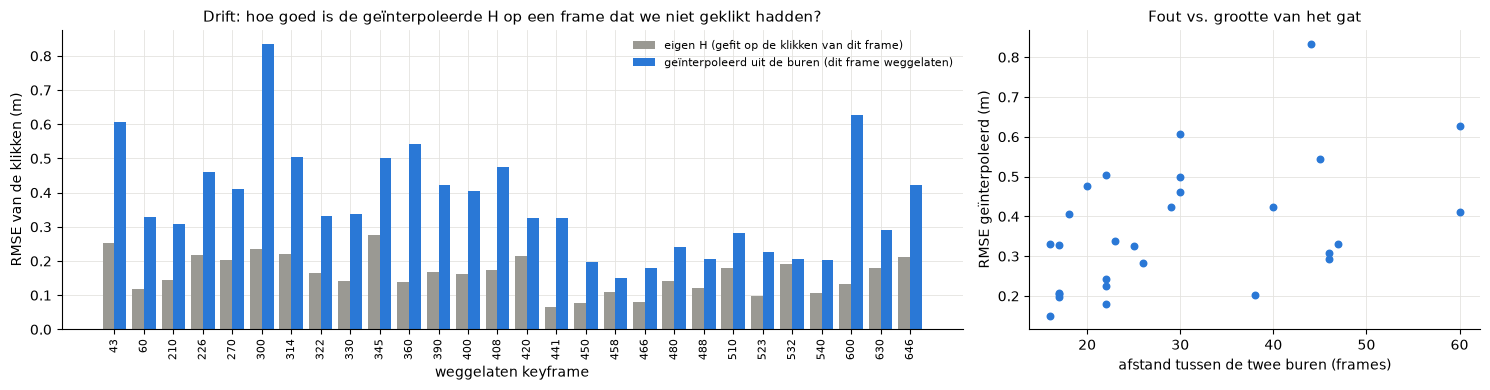

In [15]:
lok = []
idx = sorted(keypoints)
for j, f in enumerate(idx[1:-1], start=1):
    if len(keypoints[f]) < 5:
        continue
    others = {g: p for g, p in keypoints.items() if g != f}
    H_interp = Homographies(others).for_frame(f)          # f is now between keyframes idx[j-1] and idx[j+1]
    e_int = reprojection_errors_m(keypoints[f], H_interp)
    H_own, _ = fit(keypoints[f])
    e_own = reprojection_errors_m(keypoints[f], H_own)
    rms = lambda e: float(np.sqrt(np.mean(np.square(list(e.values())))))
    lok.append({"frame": f, "gat_frames": idx[j + 1] - idx[j - 1], "rmse_eigen_H": rms(e_own),
                "rmse_geinterpoleerd": rms(e_int), "max_geinterpoleerd": max(e_int.values())})
lok = pd.DataFrame(lok)
print(f"{len(lok)} keyframes getest; geinterpoleerde H: RMSE mediaan {lok.rmse_geinterpoleerd.median():.2f} m, "
      f"max {lok.rmse_geinterpoleerd.max():.2f} m (frame {lok.loc[lok.rmse_geinterpoleerd.idxmax(), 'frame']}); "
      f"eigen H: mediaan {lok.rmse_eigen_H.median():.2f} m")
print(f"correlatie tussen gatgrootte en fout (Spearman): {lok.gat_frames.corr(lok.rmse_geinterpoleerd, method='spearman'):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
xx = np.arange(len(lok))
ax.bar(xx - 0.2, lok.rmse_eigen_H, 0.4, color=C["grey"], label="eigen H (gefit op de klikken van dit frame)")
ax.bar(xx + 0.2, lok.rmse_geinterpoleerd, 0.4, color=C["main"], label="geïnterpoleerd uit de buren (dit frame weggelaten)")
ax.set_xticks(xx, lok.frame, rotation=90, fontsize=8)
ax.set_xlabel("weggelaten keyframe")
ax.set_ylabel("RMSE van de klikken (m)")
ax.set_title("Drift: hoe goed is de geïnterpoleerde H op een frame dat we niet geklikt hadden?")
ax.legend(fontsize=8)
ax = axes[1]
ax.scatter(lok.gat_frames, lok.rmse_geinterpoleerd, color=C["main"], s=22)
ax.set_xlabel("afstand tussen de twee buren (frames)")
ax.set_ylabel("RMSE geïnterpoleerd (m)")
ax.set_title("Fout vs. grootte van het gat")
fig.tight_layout()
save(fig, "11_drift_keyframe_weglaten.png")
plt.show()

Dezelfde truc voor de interpolatie: we laten een hele keyframe weg, laten de app zijn $H$ interpoleren uit de twee buren
en meten de reprojectiefout van de klikken van het weggelaten frame. Dat is precies wat er gebeurt op een frame dat
nooit geklikt is, alleen met een **groter gat** (de afstand tussen de buren), dus de uitkomst is een bovengrens.

**Wat zien we:** waar de eigen $H$ mediaan 0,16 m haalt, haalt de geïnterpoleerde $H$ mediaan **0,33 m**; het slechtste
geval is frame 300 met 0,83 m. Grotere gaten geven gemiddeld grotere fouten (Spearman 0,48), maar de snelheid van de
camera telt even zwaar: rond frame 300 pant en zoomt de camera tegelijk. De echte drift op een niet-geklikt frame ligt
lager, omdat het gat daar maar half zo groot is.

### 5.5 Drift over alle frames: liggen de geprojecteerde lijnen op witte pixels?

recomputed vs saved csv: max |verschil| 0.0000
mediaan op keyframes 0.51, grens 0.38; alle frames: mediaan 0.51, min 0.23; 106 frames onder de grens, waarvan 10 keyframes: [150, 420, 441, 458, 466, 480, 488, 510, 523, 540]


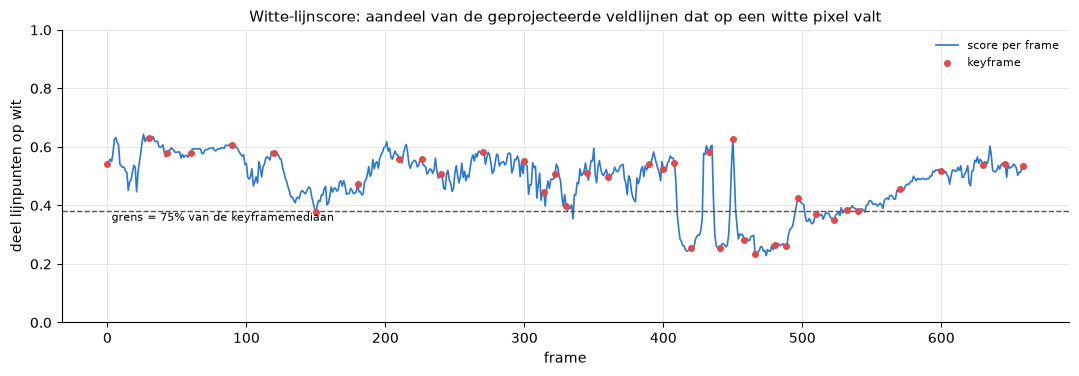

keyframes: correlatie witte-lijnscore vs. RMSE (Spearman) = 0.36
RMSE van de zwak scorende keyframes (m): {420: 0.21, 441: 0.07, 458: 0.11, 466: 0.08, 480: 0.14, 488: 0.12, 510: 0.18, 523: 0.1, 540: 0.11}


In [16]:
from check_homography import RELATIVE_LIMIT, white_mask   # same check as the command-line tool

dense = np.concatenate(dense_lines())
scores = {}
for f, frame in iter_frames(VIDEO, range(N)):
    p = hs.pitch_to_image(dense, f)
    inside = (p[:, 0] >= 0) & (p[:, 0] < W_IMG) & (p[:, 1] >= 0.15 * H_IMG) & (p[:, 1] < H_IMG)
    p = p[inside].astype(int)
    scores[f] = float(white_mask(frame)[p[:, 1], p[:, 0]].mean()) if len(p) > 50 else np.nan
drift = pd.DataFrame({"frame": list(scores), "score": list(scores.values())})
drift["keyframe"] = drift.frame.isin(hs.keyframes)
saved = pd.read_csv(RES / "homography_check.csv")
print(f"recomputed vs saved csv: max |verschil| {(saved.score - drift.score.round(3)).abs().max():.4f}")

ref = drift.score[drift.keyframe].median()
limit = RELATIVE_LIMIT * ref
weak_kf = drift.frame[drift.keyframe & (drift.score < limit)].tolist()
print(f"mediaan op keyframes {ref:.2f}, grens {limit:.2f}; alle frames: mediaan {drift.score.median():.2f}, "
      f"min {drift.score.min():.2f}; {int((drift.score < limit).sum())} frames onder de grens, waarvan "
      f"{len(weak_kf)} keyframes: {weak_kf}")

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(drift.frame, drift.score, color=C["main"], lw=1.2, label="score per frame")
k = drift[drift.keyframe]
ax.scatter(k.frame, k.score, color=C["warn"], s=16, zorder=3, label="keyframe")
ax.axhline(limit, color=C["ink"], ls="--", lw=1)
ax.text(3, limit - 0.035, f"grens = {RELATIVE_LIMIT:.0%} van de keyframemediaan", fontsize=8)
ax.set_xlabel("frame")
ax.set_ylabel("deel lijnpunten op wit")
ax.set_ylim(0, 1)
ax.set_title("Witte-lijnscore: aandeel van de geprojecteerde veldlijnen dat op een witte pixel valt")
ax.legend(fontsize=8, loc="upper right")
save(fig, "12_witte_lijnscore.png")
plt.show()

both = rep.merge(drift, on="frame")
both = both[both.checkable]
print(f"keyframes: correlatie witte-lijnscore vs. RMSE (Spearman) = {both.score.corr(both.rmse_m, method='spearman'):.2f}")
print("RMSE van de zwak scorende keyframes (m):",
      both[both.frame.isin(weak_kf)].set_index("frame").rmse_m.round(2).to_dict())

De laatste controle (uit `check_homography.py`) werkt zonder klikken: projecteer alle veldlijnen met de $H$ van het
frame in het beeld en tel welk deel van die lijnpunten op een witte pixel valt (helder en grijs in HSV, 4 px
tolerantie, de bovenste 15 % van het beeld genegeerd). Een frame dat duidelijk lager scoort dan de keyframes, wordt
gemarkeerd als "gedrift".

**Wat zien we:**
- De herberekening valt exact samen met de opgeslagen csv.
- De score ligt meestal rond 0,5-0,6; 106 frames zakken onder de grens van 0,38. Opvallend is de diepe dip van frame
  ±415 tot ±500 (score ±0,25), onderbroken door twee pieken precies op keyframes 433 en 450.
- **De 10 keyframes die laag scoren** (150, 420, 441, 458, 466, 480, 488, 510, 523, 540) zijn dezelfde 10 die in
  `WIJZIGINGEN.md` als "herbekijken waard" stonden en in de projectgeschiedenis als "herklikken". Ze zijn in de huidige
  `keypoints.json` **niet opnieuw geklikt** (de cijfers zijn identiek aan de opgeslagen controle).
- Hun klikken zijn nochtans goed: de reprojectiefout van deze keyframes is laag (0,07-0,21 m; frame 150 heeft 4 punten
  en is niet te controleren), en over alle keyframes hangt de witte-lijnscore zelfs licht **positief** samen met de
  RMSE (Spearman 0,36). Een lage score betekent hier dus niet "slechte klikken". Wat dan wel? Dat zoeken we hieronder uit.

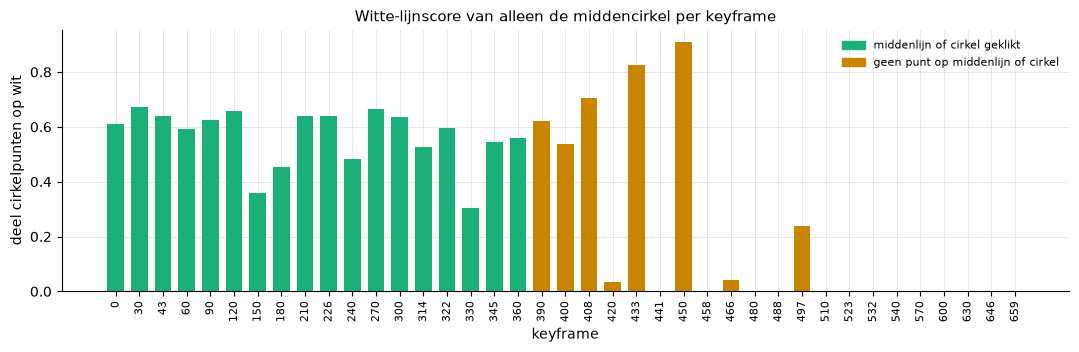

keyframes vanaf 420: cirkelscore 0 op 15 van 18; uitzonderingen: [433, 450]
reference keyframes: [390, 400, 408, 433, 450]


frame 420: reference circle on white 76%; own H puts the visible circle 1.46 m (median) to 1.88 m (max) off


frame 441: reference circle on white 83%; own H puts the visible circle 1.22 m (median) to 1.51 m (max) off


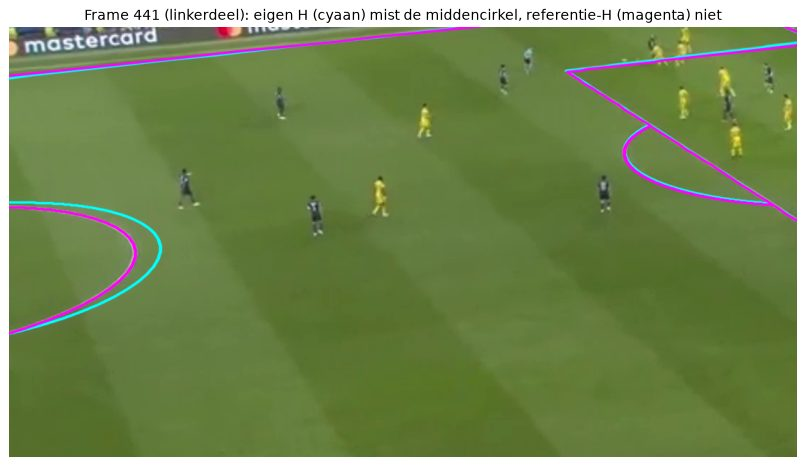

In [17]:
# Which line is missed on the weak keyframes? White score of the centre circle alone, per keyframe, with its own H
circle = LINES[2]
circ = []
for f, frame in iter_frames(VIDEO, sorted(keypoints)):
    p = project(circle, np.linalg.inv(hs.keyframes[f]))
    inside = (p[:, 0] >= 0) & (p[:, 0] < W_IMG) & (p[:, 1] >= 0.15 * H_IMG) & (p[:, 1] < H_IMG)
    p = p[inside].astype(int)
    circ.append({"frame": f, "cirkelscore": white_mask(frame)[p[:, 1], p[:, 0]].mean() if len(p) > 5 else np.nan,
                 "middenpunten_geklikt": any(n in keypoints[f] for n in ("centre", "circle_T", "circle_B", "mid_T", "mid_B"))})
circ = pd.DataFrame(circ)

fig, ax = plt.subplots(figsize=(13, 3.4))
xx = np.arange(len(circ))
ax.bar(xx, circ.cirkelscore, width=0.7,
       color=[C["second"] if m else C["extra"] for m in circ.middenpunten_geklikt])
ax.set_xticks(xx, circ.frame, rotation=90, fontsize=8)
ax.set_xlabel("keyframe")
ax.set_ylabel("deel cirkelpunten op wit")
ax.set_title("Witte-lijnscore van alleen de middencirkel per keyframe")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C["second"], label="middenlijn of cirkel geklikt"),
                   Patch(color=C["extra"], label="geen punt op middenlijn of cirkel")], fontsize=8, loc="upper right")
save(fig, "12b_cirkelscore.png")
plt.show()
late = circ[circ.frame >= 420]
print(f"keyframes vanaf 420: cirkelscore 0 op {int((late.cirkelscore < 0.05).sum())} van {len(late)}; "
      f"uitzonderingen: {late[late.cirkelscore >= 0.5].frame.tolist()}")

# How far off is the own H at the circle? Reference: H interpolated from neighbouring keyframes whose circle DOES
# lie on the white circle (390-450, score >= 0.5), evaluated on frames 420 and 441 that lie between them.
good = circ[(circ.frame.between(390, 450)) & (circ.cirkelscore >= 0.5)].frame.tolist()
ref = Homographies({g: keypoints[g] for g in good})
print("reference keyframes:", good)
for f in (420, 441):
    img = project(circle, np.linalg.inv(ref.for_frame(f)))            # where the real circle is in the image
    ins = (img[:, 0] >= 0) & (img[:, 0] < W_IMG) & (img[:, 1] >= 0.15 * H_IMG) & (img[:, 1] < H_IMG)
    on_white = white_mask(read_frame(VIDEO, f))[img[ins, 1].astype(int), img[ins, 0].astype(int)].mean()
    d = np.linalg.norm(project(img[ins], hs.keyframes[f]) - circle[ins], axis=1)  # own H maps them here
    print(f"frame {f}: reference circle on white {on_white:.0%}; own H puts the visible circle "
          f"{np.median(d):.2f} m (median) to {d.max():.2f} m (max) off")

f = 441
frame = read_frame(VIDEO, f)
both_img = overlay_lines(frame, hs.keyframes[f], colour=(255, 255, 0), thickness=2)
both_img = overlay_lines(both_img, ref.for_frame(f), colour=(255, 0, 255), thickness=2)
fig, ax = plt.subplots(figsize=(12, 6.2))
ax.imshow(rgb(both_img[300:900, 0:1100]))
ax.set_title(f"Frame {f} (linkerdeel): eigen H (cyaan) mist de middencirkel, referentie-H (magenta) niet")
ax.axis("off")
show_photo(fig, "12c_cirkel_frame441.png")

**Wat zien we:** de oorzaak is de **middencirkel**. Tot keyframe 408 valt de geprojecteerde cirkel grotendeels op de
witte cirkel (score 0,3-0,7); tot 360 is er telkens een punt op de middenlijn of de cirkel zelf geklikt. Vanaf keyframe 420
liggen alle klikken rond het strafschopgebied, 35 m of meer van de cirkel. Op 15 van de 18 keyframes vanaf 420 valt
**geen enkel** cirkelpunt op wit. De twee uitzonderingen (433 en 450, met maar 4 en 5 punten) zijn precies de pieken in
de score hierboven.

Hoe groot is die fout in meters? Op frames 420 en 441 kunnen we het schatten met een referentie-$H$, geïnterpoleerd uit
de keyframes 390-450 waarvan de cirkel wel op het wit ligt (76-83 % van de referentiecirkel valt op witte pixels). De
eigen $H$ van die keyframes zet de zichtbare cirkel **1,2-1,5 m** (mediaan) en tot 1,9 m naast zijn echte plek. In de
uitsnede zie je dat: de cyaan cirkel ligt duidelijk rechts van de witte, de magenta valt erop.

Wat betekent dat?
- De klikken zijn niet fout en herklikken lost niets op. Het probleem is **extrapolatie**: een $H$ die op een gebied van
  ±10 % van het veld gefit is, klopt op 35 m daarvandaan tot op 1-2 m. Dat sluit aan bij de weglaat-test van 5.3
  (fout buiten het klikgebied p90 1,15 m, oplopend met de afstand).
- De reprojectiefout van 5.1 kan dit **niet** zien: ze meet alleen op de geklikte punten zelf.
- De oplossing zou een klik ver van het strafschopgebied zijn. In deze frames is van de middencirkel echter alleen
  een boog zichtbaar, zonder benoemd punt van het veldmodel (de snijpunten met de middenlijn liggen buiten beeld). Een
  fit op lijnen of bogen in plaats van op punten zou dat oplossen; dat hebben we niet gebouwd.
- Voor de minimap betekent dit dat spelers bij de middencirkel in het tweede deel van de clip tot ±1,5 m verschoven
  kunnen staan; spelers in en rond het strafschopgebied (waar het spel zich dan afspeelt) staan wel goed.

Conclusie van sectie 5: de klikken zijn nauwkeurig (±0,16 m), de interpolatie voegt hooguit enkele tienden van een meter
toe, maar ver van de klikken loopt de fout op tot 1-2 m. De witte-lijnscore is het enige van de checks die dat
laatste opmerkt.

## 6. Visueel bewijs

Cijfers zijn één ding; de beste controle is kijken. We nemen vier frames verspreid over de clip die **geen** keyframe
zijn, zodat we de geïnterpoleerde $H$ zien. Eerst tekenen we het veldmodel in het beeld (veld -> beeld, met $H^{-1}$),
daarna doen we het omgekeerde en "ontvouwen" we het beeld tot een bovenaanzicht met `cv2.warpPerspective`.

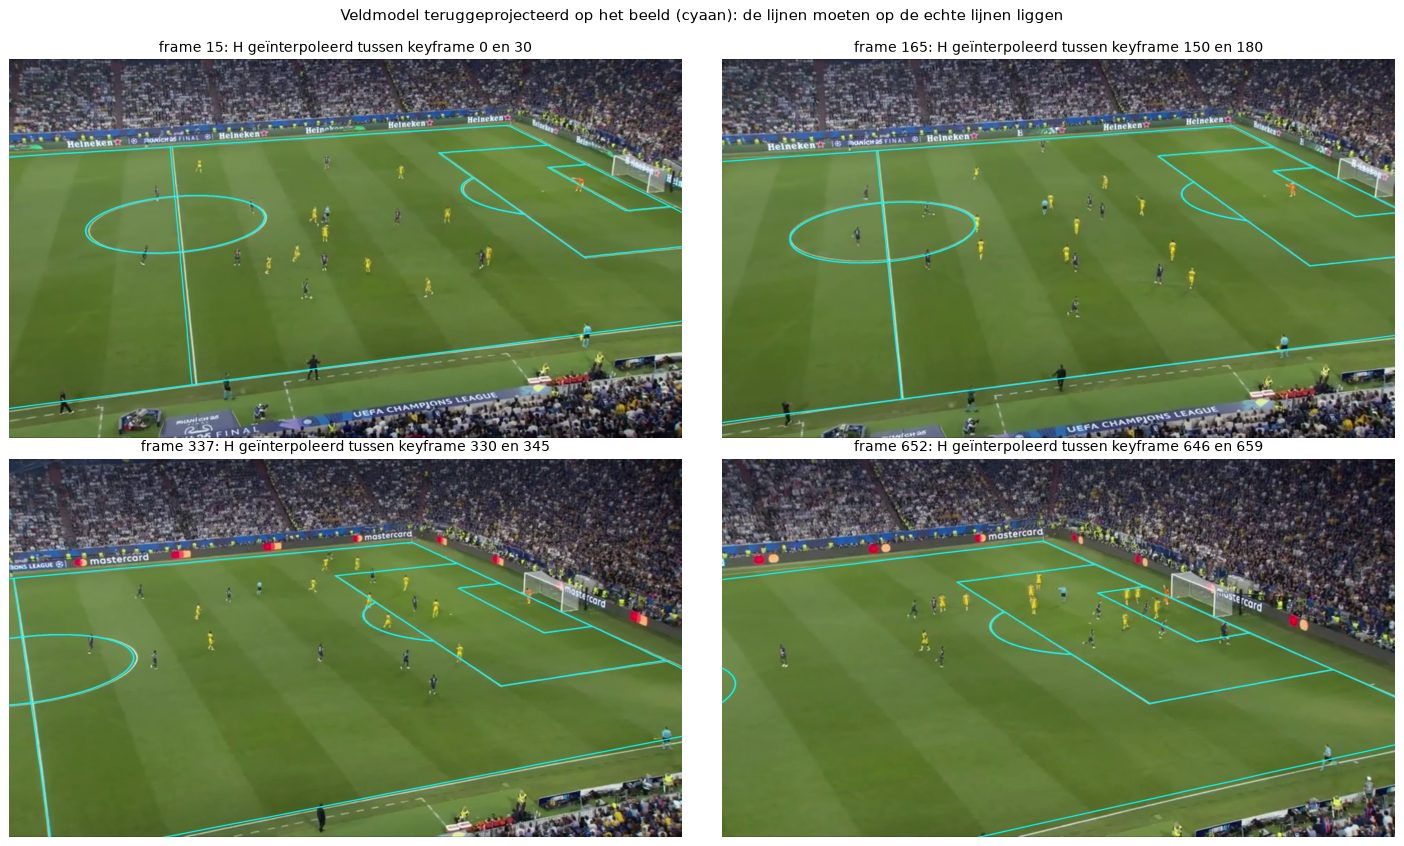

In [18]:
frames_check = [15, 165, 337, 652]          # none of these is a keyframe: H is interpolated
assert not set(frames_check) & set(hs.keyframes)
fig, axes = plt.subplots(2, 2, figsize=(16, 9.4))
for ax, f in zip(axes.ravel(), frames_check):
    a = max(i for i in hs.keyframes if i < f)
    b = min(i for i in hs.keyframes if i > f)
    ax.imshow(rgb(overlay_lines(read_frame(VIDEO, f), hs.for_frame(f))))
    ax.set_title(f"frame {f}: H geïnterpoleerd tussen keyframe {a} en {b}")
    ax.axis("off")
fig.suptitle("Veldmodel teruggeprojecteerd op het beeld (cyaan): de lijnen moeten op de echte lijnen liggen", y=0.995)
fig.tight_layout()
show_photo(fig, "13_lijnen_op_beeld.png")

**Wat zien we:** in alle vier de frames vallen de cyaan lijnen op de witte lijnen van het veld: de middenlijn en de
middencirkel (frame 15 en 165), het strafschopgebied, het doelgebied en de boog (337 en 652), en ook de zijlijnen aan
de rand van het beeld. Een fout van een halve meter is op deze schaal enkele pixels; daarom zoomen we hieronder in.

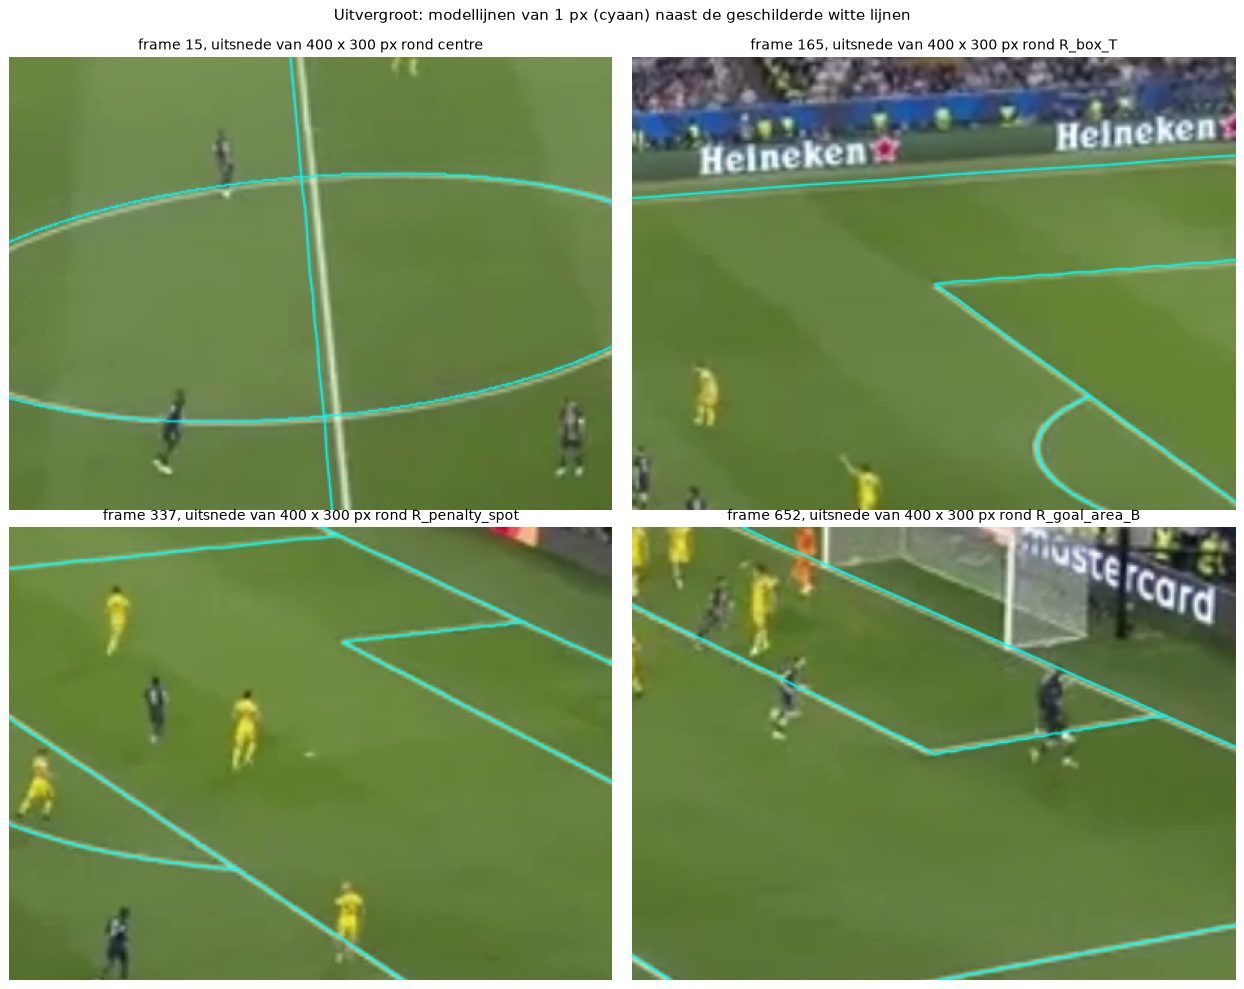

In [19]:
# Full-resolution crops with 1 px lines: here a misfit of a few pixels would be visible
crops = [(15, "centre"), (165, "R_box_T"), (337, "R_penalty_spot"), (652, "R_goal_area_B")]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (f, name) in zip(axes.ravel(), crops):
    img = overlay_lines(read_frame(VIDEO, f), hs.for_frame(f), thickness=1)
    cx, cy = hs.pitch_to_image([KEYPOINTS[name]], f)[0].astype(int)
    x0, y0 = int(np.clip(cx - 200, 0, W_IMG - 400)), int(np.clip(cy - 150, 0, H_IMG - 300))
    ax.imshow(rgb(img[y0:y0 + 300, x0:x0 + 400]))
    ax.set_title(f"frame {f}, uitsnede van 400 x 300 px rond {name}")
    ax.axis("off")
fig.suptitle("Uitvergroot: modellijnen van 1 px (cyaan) naast de geschilderde witte lijnen", y=0.995)
fig.tight_layout()
show_photo(fig, "13b_lijnen_uitvergroot.png")

**Wat zien we:** in frames 165, 337 en 652 liggen de lijnen van 1 pixel op of tegen de geschilderde lijnen. In
**frame 15** is wel een afwijking te zien: de modelmiddenlijn ligt enkele pixels links van de echte middenlijn, en de
cirkel loopt er net naast. Frame 15 ligt tussen keyframe 0 (10 punten, goed) en keyframe 30, die maar 4 punten heeft en
dus niet te controleren is. Dit is precies het soort drift dat de witte-lijnscore niet opmerkt en die de weglaat-test
van 5.4 op ordegrootte een paar tienden van een meter schat. Een extra keyframe met meer punten rond frame 15-30 zou
dit verbeteren.

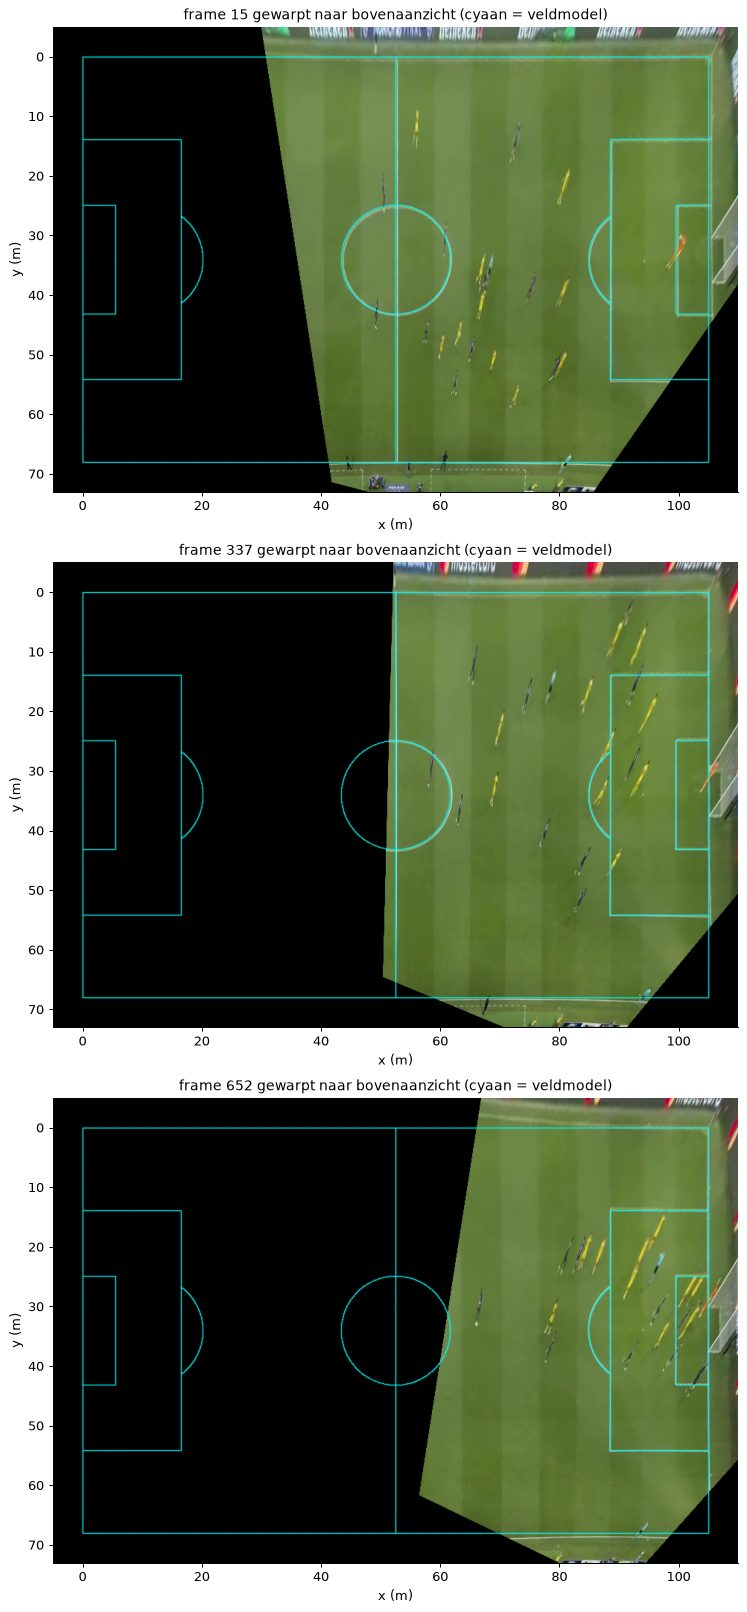

In [20]:
SCALE, MARGIN = 8, 5                         # top view: 8 px per metre, 5 m margin
S = np.array([[SCALE, 0, MARGIN * SCALE], [0, SCALE, MARGIN * SCALE], [0, 0, 1]], float)
size = (int((LENGTH + 2 * MARGIN) * SCALE), int((WIDTH + 2 * MARGIN) * SCALE))
fig, axes = plt.subplots(3, 1, figsize=(10, 18))
for ax, f in zip(axes, [15, 337, 652]):
    top = cv2.warpPerspective(read_frame(VIDEO, f), S @ hs.for_frame(f), size)   # image -> pitch -> top-view px
    for pts in dense_lines():
        q = np.round((pts + MARGIN) * SCALE).astype(np.int32)
        cv2.polylines(top, [q], False, (255, 255, 0), 1, cv2.LINE_AA)
    ax.imshow(rgb(top), extent=(-MARGIN, LENGTH + MARGIN, WIDTH + MARGIN, -MARGIN))
    ax.set_title(f"frame {f} gewarpt naar bovenaanzicht (cyaan = veldmodel)")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.grid(False)
fig.tight_layout()
show_photo(fig, "14_warp_bovenaanzicht.png")

**Wat zien we:** het gewarpte beeld past op het veldmodel: de geschilderde lijnen van het strafschopgebied en de
middencirkel vallen op de dunne cyaan lijnen. Twee dingen tonen meteen de grens van een homografie:
- **Spelers worden lange strepen** die van de camera weg wijzen (naar boven, kleine y). Alleen hun voeten liggen in het
  grasvlak en staan dus op de juiste plek; hun lichaam wordt behandeld alsof het plat op het gras ligt.
- Boven de verre zijlijn (y < 0) en onder de dichtbije zijlijn (y > 68) zie je reclameborden en tribune "op het veld":
  die staan rechtop en horen niet bij het grasvlak.

## 7. De minimap

De minimap (`core/pipeline.py`) gebruikt de homografie zo:
- **spelers**: het **voetpunt** = het midden van de onderkant van de detectiebox, $((x_1 + x_2)/2,\ y_2)$, omgezet met de
  $H$ van dat frame. Detecties die meer dan 3 m buiten de lijnen vallen, worden weggelaten.
- **bal**: het **midden van de balbox**, omgezet met dezelfde $H$; een "bal" binnen 1 m van een geschilderde stip wordt
  genegeerd (de stip lijkt op een bal).

Tracking, teamtoewijzing, balbezit en de analyses worden uitgelegd in notebooks 04 tot 06; de volledige
systeemevaluatie tegen de ground truth in notebook 06. Hier
gebruiken we het eindresultaat van de pipeline met het finale model (uit de detectiecache, er draait geen YOLO).
De kleuren zijn die van de app: donkerblauw = PSG (team A), geel = Inter (team B), oranje = keeper van Inter,
zwart = scheidsrechter; wit = de bal.

660 frames, model psg_vs_inter_CV.pt; frames with people: 660, frames with a ball position: 499


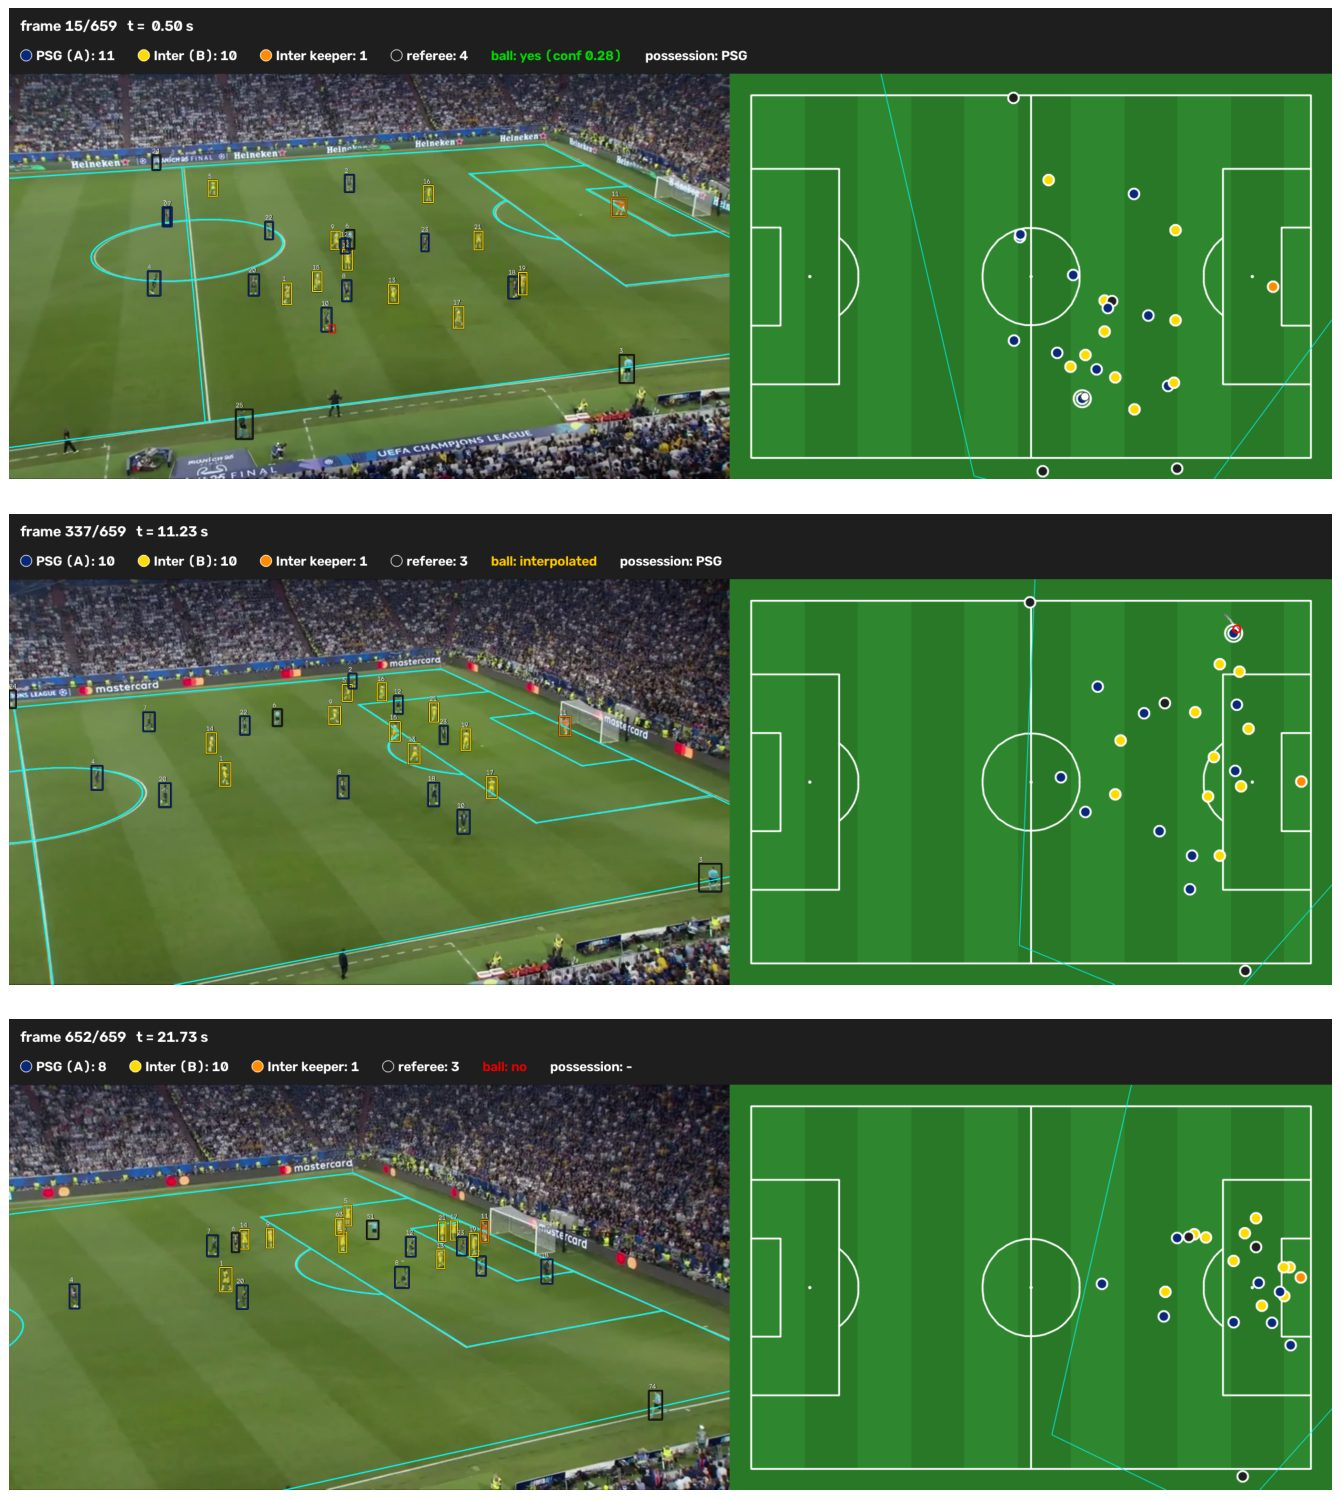

In [21]:
import core.pipeline as pipe
from core.render import render_frame

result = pipe.run()          # reads the detections of the final model from ../streamlit/cache (no YOLO run)
print(f"{len(result.ids)} frames, model {Path(result.weights).name}; frames with people: "
      f"{sum(bool(result.people[i]) for i in result.ids)}, frames with a ball position: {len(result.ball)}")

fig, axes = plt.subplots(3, 1, figsize=(15, 17))
for ax, f in zip(axes, [15, 337, 652]):
    ax.imshow(rgb(render_frame(read_frame(VIDEO, f), f, result)))
    ax.axis("off")
fig.tight_layout()
show_photo(fig, "15_frame_en_minimap.png")

**Wat zien we:** links het beeld met de boxen en de teruggeprojecteerde lijnen, rechts de minimap met dezelfde spelers
als stippen. De onderlinge posities kloppen met het beeld: in frame 652 staat een kluwen spelers in het strafschopgebied,
de keeper staat voor zijn doel. De homografie werkt dus voor spelers op het gras.

De dunne cyaan veelhoek op de minimap is in de app bedoeld als "wat de camera ziet": de vier hoeken van het beeld
omgerekend naar het veld. De bovenste hoeken van het beeld liggen echter in de tribune, boven het grasvlak, en komen
daardoor op onzinnige plekken terecht (schuine lijnen tot buiten het veld). Dat is een weergavefout van die ene
veelhoek, niet van de spelersposities; sectie 4 rekent het zichtbare veld correct uit. Toch zijn er drie bronnen van
**systematische** fouten, die we hieronder meten.

### 7.1 Hoeveel meter is één pixel?

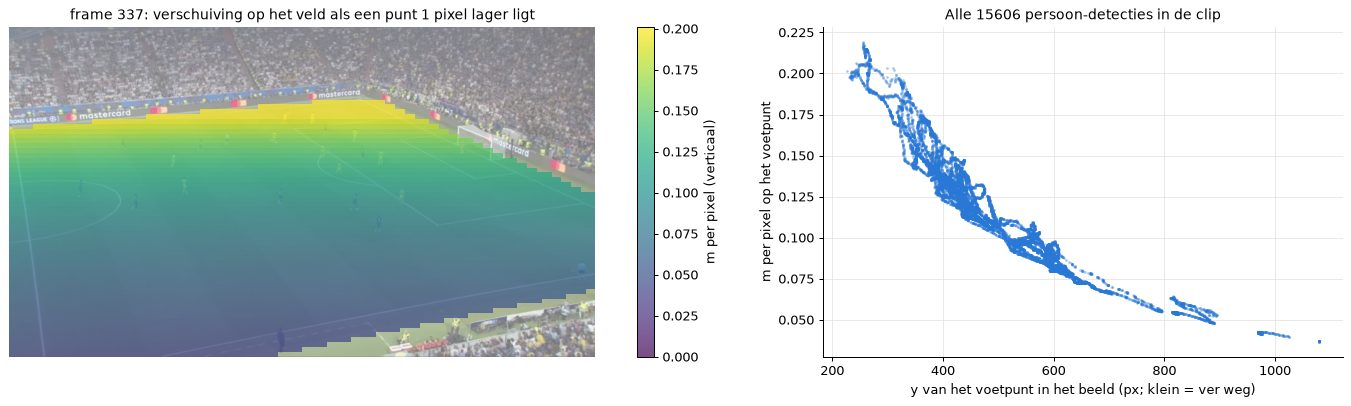

m per pixel op het voetpunt: p5 0.061, mediaan 0.118, p95 0.181 m/px -> een voetpunt 5 px te hoog kost 0.31 .. 0.90 m


In [22]:
f = 337
H = hs.for_frame(f)
xs, ys = np.meshgrid(np.arange(0, W_IMG, 16), np.arange(0, H_IMG, 16))
p0 = np.c_[xs.ravel(), ys.ravel()].astype(float)
m0, m1 = project(p0, H), project(p0 + [0, 1], H)
mpp = np.linalg.norm(m1 - m0, axis=1).reshape(xs.shape)
on = ((m0[:, 0] > -3) & (m0[:, 0] < LENGTH + 3) & (m0[:, 1] > -3) & (m0[:, 1] < WIDTH + 3)).reshape(xs.shape)
mpp = np.where(on, mpp, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.imshow(rgb(read_frame(VIDEO, f)), alpha=0.55)
im = ax.imshow(mpp, extent=(0, W_IMG, H_IMG, 0), cmap="viridis", alpha=0.7, vmin=0, vmax=np.nanpercentile(mpp, 98))
fig.colorbar(im, ax=ax, label="m per pixel (verticaal)")
ax.set_title(f"frame {f}: verschuiving op het veld als een punt 1 pixel lager ligt")
ax.axis("off")

# Same quantity at the foot point of every detected person in every frame
feet = []
for i in result.ids:
    Hi = hs.for_frame(i)
    for p in result.people[i]:
        x1, y1, x2, y2 = p["box"]
        a = project([[(x1 + x2) / 2, y2], [(x1 + x2) / 2, y2 + 1], [(x1 + x2) / 2, y1]], Hi)
        feet.append({"frame": i, "team": p["team"], "y_voet": y2, "m_per_px": np.linalg.norm(a[1] - a[0]),
                     "kop_vs_voet_m": np.linalg.norm(a[2] - a[0]), "box_h": y2 - y1})
feet = pd.DataFrame(feet)
ax = axes[1]
ax.scatter(feet.y_voet, feet.m_per_px, s=2, alpha=0.25, color=C["main"])
ax.set_xlabel("y van het voetpunt in het beeld (px; klein = ver weg)")
ax.set_ylabel("m per pixel op het voetpunt")
ax.set_title(f"Alle {len(feet)} persoon-detecties in de clip")
fig.tight_layout()
show_photo(fig, "16_meter_per_pixel.png")
q = feet.m_per_px.quantile([0.05, 0.5, 0.95])
print(f"m per pixel op het voetpunt: p5 {q[0.05]:.3f}, mediaan {q[0.5]:.3f}, p95 {q[0.95]:.3f} m/px "
      f"-> een voetpunt 5 px te hoog kost {5 * q[0.05]:.2f} .. {5 * q[0.95]:.2f} m")

Hoe gevoelig is de positie voor een fout van één pixel? We verschuiven elk beeldpunt 1 pixel naar beneden en meten hoe
ver het op het veld verplaatst.

**Wat zien we:** op de kaart loopt de gevoeligheid van onder (dicht bij de camera) naar boven (de verre zijlijn)
sterk op. Over alle persoon-detecties van de clip is één pixel op het voetpunt 0,06 m (p5) tot 0,18 m (p95), mediaan
0,12 m: een factor 3 tussen dichtbij en ver weg. Een voetpunt dat 5 pixels
te hoog ligt (een iets te ruime of te krappe box, een voet die achter een andere speler zit) kost dus 0,3 tot 0,9 m.
Spelers ver van de camera zijn het minst nauwkeurig: hun box is klein en elk pixel weegt zwaar.

### 7.2 Punten boven het grasvlak: de bal in de lucht

bovenkant van de box (hoofd) via H naar het veld, afstand tot het voetpunt: p5 4.5 m, mediaan 6.8 m, p95 8.6 m
hoogte van de balbox: mediaan 14 px
bal (n=308 gedetecteerd): midden van de box vs. onderkant van de box op het veld: mediaan 0.91 m, p95 1.51 m


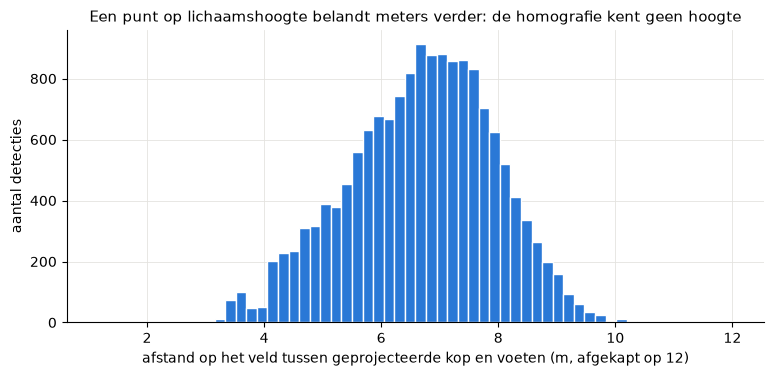

In [23]:
q = feet.kop_vs_voet_m.quantile([0.05, 0.5, 0.95])
print(f"bovenkant van de box (hoofd) via H naar het veld, afstand tot het voetpunt: "
      f"p5 {q[0.05]:.1f} m, mediaan {q[0.5]:.1f} m, p95 {q[0.95]:.1f} m")

balls = []
for i, b in result.ball.items():
    if b["state"] != "detected" or b["box"] is None:
        continue
    x1, y1, x2, y2 = b["box"]
    a = project([[(x1 + x2) / 2, (y1 + y2) / 2], [(x1 + x2) / 2, y2]], hs.for_frame(i))
    balls.append(np.linalg.norm(a[1] - a[0]))
balls = np.array(balls)
ball_h = [b["box"][3] - b["box"][1] for b in result.ball.values() if b["state"] == "detected" and b["box"]]
print(f"hoogte van de balbox: mediaan {np.median(ball_h):.0f} px")
print(f"bal (n={len(balls)} gedetecteerd): midden van de box vs. onderkant van de box op het veld: "
      f"mediaan {np.median(balls):.2f} m, p95 {np.percentile(balls, 95):.2f} m")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(feet.kop_vs_voet_m.clip(upper=12), bins=60, color=C["main"], edgecolor="white")
ax.set_xlabel("afstand op het veld tussen geprojecteerde kop en voeten (m, afgekapt op 12)")
ax.set_ylabel("aantal detecties")
ax.set_title("Een punt op lichaamshoogte belandt meters verder: de homografie kent geen hoogte")
save(fig, "17_hoogtefout.png")
plt.show()

Een homografie kent geen hoogte. Om te zien hoeveel dat uitmaakt, projecteren we voor elke persoon-detectie ook de
**bovenkant** van de box (het hoofd) alsof die op het gras lag, en meten de afstand tot het voetpunt.

**Wat zien we:**
- Een punt op hoofdhoogte belandt mediaan **6,8 m** (p5-p95: 4,5-8,6 m) verder van de camera dan de voeten. Daarom
  meten we spelers aan hun voeten, en daarom gaf de eerste ground truth (geklikt op het lichaam, niet op de voeten)
  schijnbaar posities die 3-4 m fout waren (`WIJZIGINGEN.md`).
- **Een bal in de lucht** ondergaat hetzelfde: een hoge bal of een kopbal wordt meters te ver van de camera op de
  minimap gezet. Zonder een tweede camera of een balbaanmodel kunnen we de hoogte niet weten; de pipeline doet geen poging.
- Ook **een rollende bal** krijgt een kleine vaste fout: de pipeline projecteert het **midden** van de balbox, terwijl
  het contactpunt met het gras de **onderkant** is. Dat verschil is op het veld mediaan **0,91 m** (p95 1,51 m), omdat
  een balbox mediaan 14 px hoog is en elk pixel ±0,12 m weegt. De bal staat op de minimap dus systematisch iets te
  ver van de camera (kleinere y). De ground truth kan dit niet zien: ook de balklik wordt met dezelfde homografie
  omgerekend.

### 7.3 Rand van het beeld en buiten het geklikte gebied

persoon-detecties die de beeldrand raken (voetpunt mogelijk afgesneden): 0.8% (124 van 15606)


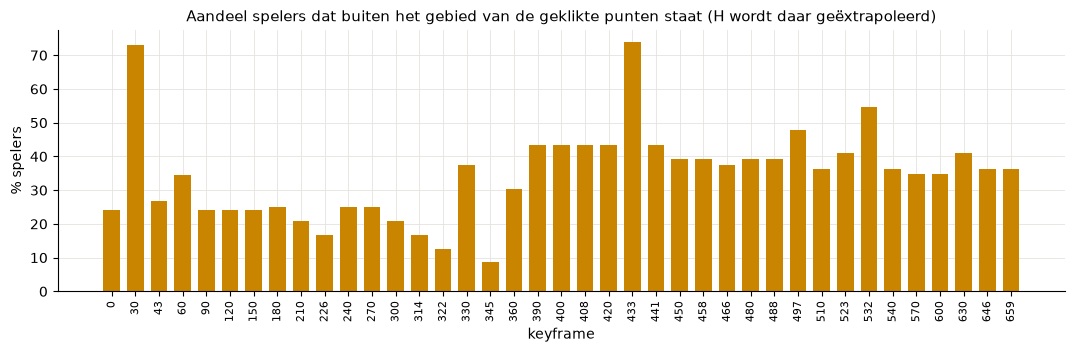

gemiddeld 35% van de spelers op een keyframe staat buiten het klikgebied; frames 0-345: 26%, frames 360-659: 42%


In [24]:
edge = []
for i in result.ids:
    for p in result.people[i]:
        x1, y1, x2, y2 = p["box"]
        edge.append(x1 <= 2 or y1 <= 2 or x2 >= W_IMG - 2 or y2 >= H_IMG - 2)
print(f"persoon-detecties die de beeldrand raken (voetpunt mogelijk afgesneden): {np.mean(edge):.1%} "
      f"({int(np.sum(edge))} van {len(edge)})")

outside = []
for f in sorted(hs.keyframes):
    hull = cv2.convexHull(np.array([KEYPOINTS[n] for n in keypoints[f]], np.float32))
    d = [max(0.0, -cv2.pointPolygonTest(hull, (p["x_m"], p["y_m"]), True)) for p in result.people[f]]
    outside.append({"frame": f, "deel_buiten": np.mean(np.array(d) > 0), "mediaan_afstand_buiten": np.median([v for v in d if v > 0] or [0])})
outside = pd.DataFrame(outside)
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.bar(np.arange(len(outside)), 100 * outside.deel_buiten, color=C["extra"], width=0.7)
ax.set_xticks(np.arange(len(outside)), outside.frame, rotation=90, fontsize=8)
ax.set_xlabel("keyframe")
ax.set_ylabel("% spelers")
ax.set_title("Aandeel spelers dat buiten het gebied van de geklikte punten staat (H wordt daar geëxtrapoleerd)")
save(fig, "18_buiten_klikgebied.png")
plt.show()
print(f"gemiddeld {outside.deel_buiten.mean():.0%} van de spelers op een keyframe staat buiten het klikgebied; "
      f"frames 0-345: {outside[outside.frame <= 345].deel_buiten.mean():.0%}, frames 360-659: "
      f"{outside[outside.frame >= 360].deel_buiten.mean():.0%}")

**Wat zien we:**
- **Rand van het beeld:** slechts 0,8 % van de persoon-detecties raakt de beeldrand. Bij die spelers kan de box afgesneden
  zijn, zodat de onderkant niet de voeten is. Dat is een klein probleem in deze clip.
- **Buiten het klikgebied:** gemiddeld 35 % van de spelers op een keyframe staat buiten het gebied dat de geklikte punten
  omspannen; in het ingezoomde tweede deel (360-659) is dat 42 %. Volgens sectie 5.3 is de fout daar ongeveer dubbel zo
  groot als binnen het gebied, en bij de middencirkel loopt ze op tot 1,2-1,5 m (sectie 5.5).
- **Lensvervorming** (kromme lijnen aan de beeldrand) zit niet in het model: een homografie veronderstelt een perfecte
  pinhole-camera. In de overlays van sectie 6 zien we geen duidelijke kromming, maar we hebben dat niet apart gemeten.

## 8. Positienauwkeurigheid tegen de ground truth

Op 6 frames (0, 120, 240, 360, 480, 600) hebben we met de hand de **voeten** van alle spelers aangeklikt
(`../data/ground_truth_feet.json`, 140 gekoppelde spelers). De systeemevaluatie zelf (detectie, teams, bal, balbezit)
staat in notebook 06; hier kijken we alleen naar de **positiefout in meters**, want die komt van de homografie. We koppelen
GT en pipeline zoals `evaluation/metrics.py` (Hongaarse koppeling, straal 3 m) en vergelijken met het opgeslagen rapport
`../data/results/homografie/system_eval_best_feet.json`.

6 frames, 140 gekoppelde spelers (opgeslagen rapport: 140)
positiefout: gemiddeld 1.09 m, mediaan 1.03 m, p90 1.77 m  | rapport: gemiddeld 1.09, mediaan 1.03, p90 1.77
gemiddelde verschuiving pipeline - klik: dx -0.28 m, dy +1.00 m; fout na aftrekken van die vaste verschuiving: gemiddeld 0.48 m, mediaan 0.41 m
klikhoogte in de box: mediaan 0.84 (1 = onderkant); klikken >= 0.9: n=22, fout mediaan 0.43 m; klikken < 0.9: n=118, fout mediaan 1.13 m


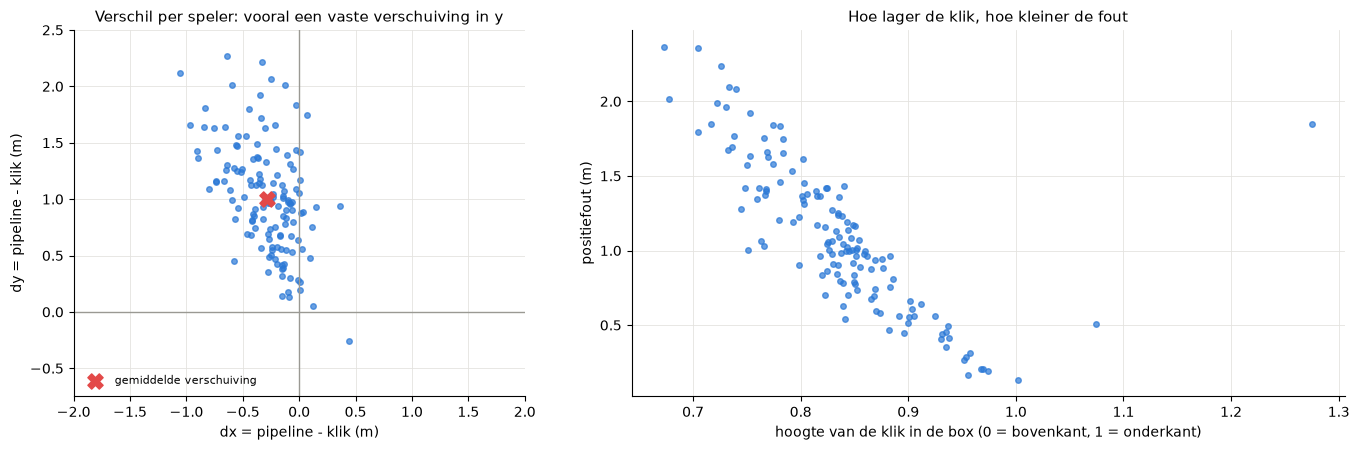

In [25]:
from evaluation.gt_format import load_gt
from evaluation.metrics import match_persons

gt = load_gt(ROOT / "data" / "ground_truth_feet.json")
pairs = []
for f, rec in sorted(gt.items()):
    persons = rec["persons"]
    preds = [{"x": p["x_m"], "y": p["y_m"], "box": p["box"]} for p in result.people[f]]
    for g_i, p_i, dist in match_persons(persons, preds, radius=3.0):
        g, p = persons[g_i], preds[p_i]
        x1, y1, x2, y2 = p["box"]
        pairs.append({"frame": f, "fout_m": dist, "dx": p["x"] - g["m"][0], "dy": p["y"] - g["m"][1],
                      "klikhoogte": (g["px"][1] - y1) / max(y2 - y1, 1)})
pairs = pd.DataFrame(pairs)
saved_eval = json.loads((RES / "system_eval_best_feet.json").read_text(encoding="utf-8"))["players"]
print(f"{len(gt)} frames, {len(pairs)} gekoppelde spelers (opgeslagen rapport: {saved_eval['position_error_m']['n']})")
print(f"positiefout: gemiddeld {pairs.fout_m.mean():.2f} m, mediaan {pairs.fout_m.median():.2f} m, "
      f"p90 {pairs.fout_m.quantile(.9):.2f} m  | rapport: gemiddeld {saved_eval['position_error_m']['mean']:.2f}, "
      f"mediaan {saved_eval['position_error_m']['median']:.2f}, p90 {saved_eval['position_error_m']['p90']:.2f}")
bias = pairs[["dx", "dy"]].mean()
rest = np.hypot(pairs.dx - bias.dx, pairs.dy - bias.dy)
print(f"gemiddelde verschuiving pipeline - klik: dx {bias.dx:+.2f} m, dy {bias.dy:+.2f} m; "
      f"fout na aftrekken van die vaste verschuiving: gemiddeld {rest.mean():.2f} m, mediaan {np.median(rest):.2f} m")
low, high = pairs[pairs.klikhoogte >= 0.9], pairs[pairs.klikhoogte < 0.9]
print(f"klikhoogte in de box: mediaan {pairs.klikhoogte.median():.2f} (1 = onderkant); klikken >= 0.9: n={len(low)}, "
      f"fout mediaan {low.fout_m.median():.2f} m; klikken < 0.9: n={len(high)}, fout mediaan {high.fout_m.median():.2f} m")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.scatter(pairs.dx, pairs.dy, s=16, color=C["main"], alpha=0.7)
ax.scatter([bias.dx], [bias.dy], s=120, marker="X", color=C["warn"], label="gemiddelde verschuiving")
ax.axhline(0, color=C["grey"], lw=1)
ax.axvline(0, color=C["grey"], lw=1)
ax.set_aspect("equal")
ax.set_xlim(-2, 2)
ax.set_ylim(-0.75, 2.5)
ax.set_xlabel("dx = pipeline - klik (m)")
ax.set_ylabel("dy = pipeline - klik (m)")
ax.set_title("Verschil per speler: vooral een vaste verschuiving in y")
ax.legend(fontsize=8, loc="lower left")
ax = axes[1]
ax.scatter(pairs.klikhoogte, pairs.fout_m, s=16, color=C["main"], alpha=0.7)
ax.set_xlabel("hoogte van de klik in de box (0 = bovenkant, 1 = onderkant)")
ax.set_ylabel("positiefout (m)")
ax.set_title("Hoe lager de klik, hoe kleiner de fout")
fig.tight_layout()
save(fig, "19_ground_truth_voeten.png")
plt.show()

**Wat zien we:**
- De herberekening geeft exact het opgeslagen rapport: **gemiddeld 1,09 m, mediaan 1,03 m, p90 1,77 m** over 140 spelers.
- Die fout is vooral een **vaste verschuiving**: de pipeline zet spelers gemiddeld 1,00 m verder in y (dichter bij de
  camera) en 0,28 m naar links. Trek je die verschuiving af, dan blijft **0,48 m** (mediaan 0,41 m) over.
- De verklaring zit in waar er geklikt is: de klikken liggen mediaan op 0,84 van de boxhoogte, dus iets boven de
  onderkant van de box. Volgens 7.1 is een paar pixels hoger al een meter. De 22 klikken die echt onderaan liggen
  (≥ 0,9) hebben een fout van mediaan 0,43 m, de rest 1,13 m.

Dit bevestigt de conclusie uit `WIJZIGINGEN.md` en de projectgeschiedenis: **de echte positiefout van spelers op de
minimap ligt tussen ±0,5 m en ±1,1 m**, waarbij 1,1 m een bovengrens is. Welke van de twee (de klik of de onderkant
van de box) het echte contactpunt is, kunnen we met deze labels niet beslissen. Ter vergelijking: de homografie alleen
(sectie 5) is binnen het klikgebied op ±0,2-0,3 m nauwkeurig; de rest komt van de box en het label. Ver van de klikken
(bij de middencirkel in het tweede deel) voegt de homografie zelf nog tot 1,5 m toe, maar daar stonden in deze 6 frames
weinig spelers. Omdat de voetklikken met dezelfde homografie naar meters zijn omgerekend, ziet deze vergelijking een
fout in $H$ zelf niet.

## 9. Conclusies

1. **Eén homografie per frame is nodig en werkt.** De camera pant van x ≈ 67 m naar x ≈ 88 m en zoomt in (zichtbaar veld
   van 64 % naar 41 %). Met 39 handmatig geklikte keyframes (305 punten) en interpolatie van een puntenrooster krijgt elk
   van de 660 frames een eigen $H$; de veldlijnen vallen in de overlays en het bovenaanzicht op de echte lijnen, met
   een zichtbare afwijking van enkele pixels op frame 15 (naast een keyframe met maar 4 punten).
2. **De klikken zijn nauwkeurig:** mediaan 2,1 px per klik, reprojectiefout per keyframe 0,07-0,28 m (mediaan 0,16 m) op
   30 controleerbare keyframes. RANSAC hoefde in de echte data geen enkele klik te verwerpen, maar beschermt tegen een
   misklik (demonstratie: 0,30 m -> 0,21 m).
3. **Tussen de keyframes** is de fout hooguit mediaan 0,33 m (weglaat-test, pessimistisch), met een uitschieter van 0,83 m
   bij de snelle camerabeweging rond frame 300.
4. **De 10 laag scorende keyframes** uit de witte-lijnscore zijn niet herklikt, en dat zou ook niet helpen: hun
   klikken zijn goed (0,07-0,21 m). De lage score komt van **extrapolatie**: vanaf frame 420 liggen alle klikken rond het
   strafschopgebied en ligt de middencirkel 1,2-1,5 m naast zijn echte plek. De reprojectiefout kan dat niet zien.
5. **De minimap** is voor spelers tot op ±0,5-1,1 m juist (ground truth, 140 spelers). De grootste fouten komen niet uit
   de matrix maar uit punten die niet op het gras liggen: een punt op hoofdhoogte belandt ±6,8 m te ver, het midden van
   een balbox ±0,9 m.

## Beperkingen

- **Handmatig en alleen voor deze clip.** De keypoints zijn met de hand geklikt voor deze ene shot van 22 s. Een nieuwe
  clip, een andere camera of zelfs een snede naar een andere camerahoek vraagt nieuwe klikken. Een automatische
  veldlijn- of keypointdetector (bv. een keypoint-model dat de veldpunten voorspelt) hebben we niet gebouwd.
- **Vlak veld, perfecte camera.** De homografie veronderstelt een plat veld en geen lensvervorming. Alles boven het gras
  (bal in de lucht, hoofden) wordt fout geplaatst; de pipeline corrigeert daar niet voor.
- **9 keyframes zijn niet controleerbaar** (4 punten), en de controle van de andere keyframes gebruikt dezelfde klikken
  als de fit. De weglaat-tests verhelpen dat deels, maar zijn op hun beurt pessimistisch (één punt of keyframe minder).
- **Weinig spreiding in het tweede deel:** vanaf frame ±390 liggen alle klikken rond het strafschopgebied; spelers bij de
  middencirkel worden geëxtrapoleerd en staan tot 1,5 m verkeerd. Het veldmodel heeft geen benoemd punt op het stuk
  cirkel dat dan zichtbaar is, dus extra klikken kunnen dit maar beperkt oplossen; een fit op lijnen en bogen wel.
- **De veldmaten zijn aangenomen** (FIFA-standaard 105 x 68 m). Als het echte veld afwijkt, schalen alle afstanden mee.
- **Ground truth is klein:** 6 frames met voetklikken, gelabeld door één persoon, met dezelfde homografie omgerekend als de
  pipeline. Een fout in $H$ zelf is in die vergelijking dus onzichtbaar; alleen de keypointcontroles van sectie 5 meten die.